# 2. Modelación
Consume el split **processed** generado al cierre de `1_EDA` (`data/processed/train|test`); no divide ni transforma datos. Entrena y evalúa los modelos con las semillas fijadas (random_state=42) y complementa los resultados con métricas adicionales (precision, PR-AUC, umbral, recall por género, importancia y K-Means).

**Modelo oficial:** HistGradientBoosting con hiperparámetros ajustados por CV (sección 11) y variables de texto (sección 13), más una **política de umbral por género y por número de géneros** calibrada en train (`src/metricas.py`, sección 10). La política no cambia el ranking del modelo (AUC, gap y lift), solo dónde se corta: reparte el recall de forma más pareja entre géneros y lo iguala entre canciones de 1, 2 y 3+ géneros.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.makedirs(os.path.join("output", "graficos"), exist_ok=True)

In [2]:
from src.pipeline import verificar_processed
from src.train import run as run_train

verificar_processed()   # Modelación no divide ni transforma: solo consume data/processed

print("Ejecutando Modelamiento (Semillas Reproducibles)...")
res_train = run_train()


[pipeline] data/processed disponible.
Ejecutando Modelamiento (Semillas Reproducibles)...
TRAIN - Entrenamiento de modelos supervisados
[train] X_train: (71706, 133) | Hit rate train: 21.0%

[train] Entrenando: Regresion Logistica ...
  AUC CV: 0.8409 | Gap CV: 0.0032 | 25.2s

[train] Entrenando: Random Forest ...
  AUC CV: 0.8235 | Gap CV: 0.0219 | 104.4s

[train] Entrenando: HistGradientBoosting ...
  AUC CV: 0.8678 | Gap CV: 0.0328 | 59.7s

                      auc_cv  auc_train_cv  gap_auc_cv   f1_cv  recall_cv  precision_cv
Regresion Logistica   0.8409        0.8441      0.0032  0.5672     0.8058        0.4377
Random Forest         0.8235        0.8454      0.0219  0.5523     0.6547        0.4787
HistGradientBoosting  0.8678        0.9006      0.0328  0.5973     0.8187        0.4701

[train] Mejor modelo por AUC en CV: HistGradientBoosting
[train] Ablacion de genero sobre HistGradientBoosting ...
[train] AUC CV con genero: 0.8678 | sin genero: 0.7067 | aporte: +0.1610
[train] Cal

## 1. Comparación de modelos en test
Los tres modelos se comparan con umbral 0.5. La última fila es el **modelo oficial**: el elegido por AUC de CV con la política de umbral de la sección 10 (mismas probabilidades, otro corte). Además del AUC se reportan precision, F1 y PR-AUC: con `class_weight="balanced"` el recall sube a costa de la precisión, y mostrar solo el recall haría ver el resultado mejor de lo que es.

In [3]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score
from src.pipeline import FEATURES_SCALE
from src.test import run as run_test, ARCHIVOS_MODELOS
from src.train import RESULTADOS_DIR   # tablas .csv: output/modelos/resultados/
from src.metricas import tabla_comparativa, verificar_kpis
from src.metricas import umbral_politica, aplicar_politica, ajustar_politica, resumen_equidad
from src import graficos as gr

X_train = pd.read_csv("data/processed/train/X_train.csv")
X_test = pd.read_csv("data/processed/test/X_test.csv")
y_test = pd.read_csv("data/processed/test/y_test.csv").squeeze()
raw_test = pd.read_csv("data/raw/test/raw_test.csv")   # mismo orden que X_test

# La evaluación final (AUC, precision, recall, F1, PR-AUC, gap, lift y KPIs) vive solo en src/test.py;
# aquí se reutiliza su resultado, que también deja resultados_test.csv, kpis_cumplidos.csv y equidad_test.csv.
res = run_test()
oficial = next(n for n in res if n.endswith("(oficial)"))
modelos = {n: joblib.load(os.path.join("output", "modelos", f)) for n, f in ARCHIVOS_MODELOS.items()}
politica = joblib.load(os.path.join("output", "modelos", "politica_umbral.joblib"))

tabla = tabla_comparativa(res)
print(f"Test: {len(y_test):,} canciones | hit rate base: {y_test.mean():.3f} (= PR-AUC de un modelo al azar)")
tabla

TEST — Evaluacion final en conjunto de prueba
[test] Regresion Logistica: AUC=0.8392 | PR-AUC=0.5713 | Precision=0.4269 | Recall=0.8031 | Lift@10%=3.04
[test] Random Forest: AUC=0.8273 | PR-AUC=0.5838 | Precision=0.4558 | Recall=0.6864 | Lift@10%=3.21
[test] HistGradientBoosting: AUC=0.8663 | PR-AUC=0.6337 | Precision=0.4577 | Recall=0.8244 | Lift@10%=3.43
[test] HistGradientBoosting + umbral por genero (oficial): Precision=0.4232 | Recall=0.7909

Equidad (test):
                                    HistGradientBoosting (umbral 0.5)  HistGradientBoosting + umbral por genero (oficial)
recall_macro_generos                                            0.559                                               0.591
recall_generos_hit_rate_bajo_10pct                              0.144                                               0.354
pct_generos_recall_kpi                                         45.872                                              48.624
marcadas_sobre_hit_rate_1                   

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC,AUC train,Gap AUC,Lift @10%,Sobreajuste
Modelo,,,,,,,,,,
Regresion Logistica,0.7383,0.4269,0.8031,0.5575,0.8392,0.5713,0.8438,0.0046,3.04,No
Random Forest,0.7674,0.4558,0.6864,0.5478,0.8273,0.5838,0.8457,0.0183,3.21,No
HistGradientBoosting,0.7634,0.4577,0.8244,0.5886,0.8663,0.6337,0.8962,0.0299,3.43,No
HistGradientBoosting + umbral por genero (oficial),0.7358,0.4232,0.7909,0.5514,0.8663,0.6337,0.8962,0.0299,3.43,No


In [4]:
kpis = verificar_kpis(res)
kpi = kpis.pivot(index="Modelo", columns="KPI", values="Cumple")
kpi["Cumple todos"] = (kpis.assign(ok=kpis["Cumple"] == "Si").groupby("Modelo")["ok"].all()
                       .map({True: "Si", False: "No"}))
kpi

KPI,AUC-ROC,Gap AUC,Lift @10%,Recall,Cumple todos
Modelo,,,,,
HistGradientBoosting,Si,Si,Si,Si,Si
HistGradientBoosting + umbral por genero (oficial),Si,Si,Si,Si,Si
Random Forest,Si,Si,Si,No,No
Regresion Logistica,Si,Si,Si,Si,Si


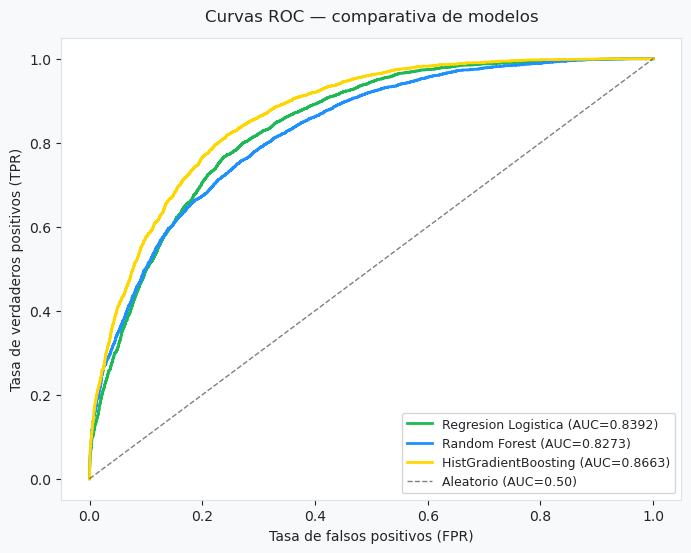

[graficos] Guardado: output\graficos\08_curvas_roc.png


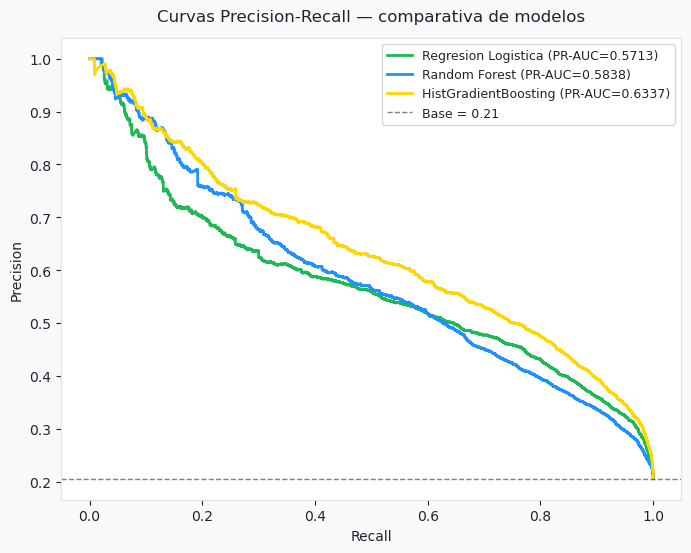

[graficos] Guardado: output\graficos\09_curvas_pr.png


In [5]:
curvas = {n: r for n, r in res.items() if n != oficial}     # el oficial comparte probabilidades con su modelo base
gr.grafico_roc(curvas, y_test)
gr.grafico_pr(curvas, y_test)

## 2. Efecto del umbral de decisión
El recall depende del umbral. Con `class_weight="balanced"` el umbral 0.5 favorece el recall y deja pasar muchos falsos positivos. Esta tabla muestra el compromiso para el mejor modelo con umbrales únicos, y al final la política oficial (un umbral distinto por canción según sus géneros).

In [6]:
cv = pd.read_csv(os.path.join(RESULTADOS_DIR, "resultados_cv.csv"), index_col=0)
mejor = res_train["mejor"] if "res_train" in globals() else cv["auc_cv"].idxmax()
m = modelos[mejor]
p = res[mejor]["y_proba"]
pred_of = res[oficial]["y_pred"]                     # predicción oficial (política de umbral)
u_of = umbral_politica(X_test[politica["features_genre"]].values, politica)
print(f"Mejor modelo (por AUC de CV): {mejor} | umbral oficial por canción: mín {u_of.min():.3f}, mediana {np.median(u_of):.3f}, máx {u_of.max():.3f}")
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
filas_u = [{"umbral": str(u),
            "precision": precision_score(y_test, (p >= u).astype(int), zero_division=0),
            "recall": recall_score(y_test, (p >= u).astype(int)),
            "f1": f1_score(y_test, (p >= u).astype(int)),
            "% de canciones marcadas como hit": (p >= u).mean() * 100} for u in umbrales]
filas_u.append({"umbral": "política oficial", "precision": precision_score(y_test, pred_of), "recall": recall_score(y_test, pred_of),
                "f1": f1_score(y_test, pred_of), "% de canciones marcadas como hit": pred_of.mean() * 100})
pd.DataFrame(filas_u).set_index("umbral").round(3)

Mejor modelo (por AUC de CV): HistGradientBoosting | umbral oficial por canción: mín 0.271, mediana 0.464, máx 0.939


,precision,recall,f1,% de canciones marcadas como hit
umbral,,,,
0.3,0.354,0.941,0.514,54.641
0.4,0.397,0.897,0.551,46.324
0.5,0.458,0.824,0.589,36.975
0.6,0.524,0.715,0.605,28.036
0.7,0.603,0.559,0.581,19.036
0.8,0.712,0.318,0.440,9.160
política oficial,0.423,0.791,0.551,38.361


### 2b. ¿Por qué `class_weight="balanced"`? (comparación con y sin)
Los tres modelos se entrenan con `class_weight="balanced"` (fijado en `src/train.py`) porque el hit rate es ≈ 20% por construcción (P80). Aquí se comprueba si eso aporta algo, usando probabilidades **fuera de muestra en train** (los mismos 5 folds agrupados de `src/train.py`); test no se usa. Se comparan dos cosas: (a) la calidad del ranking (AUC y PR-AUC), que no depende del umbral, y (b) precisión y recall con el umbral 0.5 y con un umbral calibrado para el mismo recall (0,78). Si `balanced` solo desplaza las probabilidades hacia arriba, el ranking y la precisión a igual recall serán casi iguales, y su efecto se reduciría a hacer que 0.5 sea un corte razonable.

In [7]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

y_cw = pd.read_csv("data/processed/train/y_train.csv").squeeze().values
g_cw = pd.read_csv("data/processed/train/g_train.csv").squeeze()
cv_cw = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)    # mismos folds que src/train.py
ruta_cw = os.path.join(RESULTADOS_DIR, "comparacion_class_weight.csv")

def oof_cw(nombre, cw):
    mod = clone(modelos[nombre]).set_params(clf__class_weight=cw)
    return cross_val_predict(mod, X_train, y_cw, groups=g_cw, cv=cv_cw,
                             method="predict_proba", n_jobs=1)[:, 1]

# Tarda unos minutos (3 modelos x 2 configuraciones x 5 folds); se guarda y se reutiliza (borra el csv para recalcular)
if os.path.exists(ruta_cw):
    tabla_cw = pd.read_csv(ruta_cw, index_col=[0, 1])
else:
    filas_cw = []
    for nombre in modelos:
        for cw in ("balanced", None):
            prob = oof_cw(nombre, cw)
            u78 = np.quantile(prob[y_cw == 1], 1 - 0.78)        # umbral que da recall 0.78 fuera de muestra
            p05, p78 = (prob >= 0.5).astype(int), (prob >= u78).astype(int)
            filas_cw.append({"modelo": nombre, "class_weight": str(cw),
                             "AUC (OOF)": roc_auc_score(y_cw, prob),
                             "PR-AUC (OOF)": average_precision_score(y_cw, prob),
                             "recall @0.5": recall_score(y_cw, p05),
                             "precisión @0.5": precision_score(y_cw, p05, zero_division=0),
                             "% marcadas @0.5": p05.mean() * 100,
                             "umbral recall 0.78": u78,
                             "precisión (recall 0.78)": precision_score(y_cw, p78),
                             "% marcadas (recall 0.78)": p78.mean() * 100})
    tabla_cw = pd.DataFrame(filas_cw).set_index(["modelo", "class_weight"])
    tabla_cw.to_csv(ruta_cw)

print(f"Hit rate train: {y_cw.mean():.3f}")
tabla_cw.round(4)

Hit rate train: 0.210


AUC (OOF)  PR-AUC (OOF)  recall @0.5  \
modelo               class_weight                                         
Regresion Logistica  balanced         0.8409        0.5735       0.8058   
                     None             0.8410        0.5793       0.3214   
Random Forest        balanced         0.8231        0.5843       0.6547   
                     None             0.8268        0.5996       0.1644   
HistGradientBoosting balanced         0.8678        0.6434       0.8187   
                     None             0.8671        0.6456       0.3910   

                                   precisión @0.5  % marcadas @0.5  \
modelo               class_weight                                    
Regresion Logistica  balanced              0.4376          38.6899   
                     None                  0.6460          10.4552   
Random Forest        balanced              0.4772          28.8288   
                     None                  0.8357           4.1335   
HistGradientBoosting balanced              0.4701          36.5939   
                     None                  0.6921          11.8707   

                                   umbral recall 0.78  \
modelo               class_weight                       
Regresion Logistica  balanced                  0.5294   
                     None                      0.2302   
Random Forest        balanced                  0.4872   
                     None                      0.1827   
HistGradientBoosting balanced                  0.5372   
                     None                      0.2481   

                                   precisión (recall 0.78)  \
modelo               class_weight                            
Regresion Logistica  balanced                       0.4514   
                     None                           0.4503   
Random Forest        balanced                       0.4084   
                     None                           0.4305   
HistGradientBoosting balanced                       0.4976   
                     None                           0.4931   

                                   % marcadas (recall 0.78)  
modelo               class_weight                            
Regresion Logistica  balanced                       36.3066  
                     None                           36.4000  
Random Forest        balanced                       40.1263  
                     None                           38.0735  
HistGradientBoosting balanced                       32.9387  
                     None                           33.2385

### Lectura de la sección 2b
Las cifras son AUC y PR-AUC globales sobre las probabilidades fuera de muestra de train, por lo que difieren levemente del promedio por fold que reporta `src/train.py`.

- **Ranking:** `class_weight="balanced"` no mejora la capacidad de ordenar. El AUC es prácticamente igual con y sin él en Regresión Logística (0,8409 frente a 0,8410) y en HistGradientBoosting (0,8678 frente a 0,8671), y en Random Forest es algo menor con `balanced` (0,8231 frente a 0,8268). El PR-AUC es algo menor con `balanced` en los tres modelos (HGB 0,6434 frente a 0,6456; Regresión Logística 0,5735 frente a 0,5793; Random Forest 0,5843 frente a 0,5996). Estas diferencias de PR-AUC (≤ 0,016) no se contrastaron con intervalos de confianza.
- **Umbral 0.5:** aquí está el efecto de `balanced`. En HGB, sin él el recall es 0,391 y se marca el 11,9% de las canciones (precisión 0,692); con él el recall sube a 0,819 y se marca el 36,6% (precisión 0,470). El patrón es el mismo en Regresión Logística (recall 0,806 frente a 0,321) y en Random Forest (0,655 frente a 0,164). Solo con `balanced` HGB y la Regresión Logística superan el KPI de recall (0,75) con el umbral por defecto; Random Forest no lo alcanza en ninguno de los dos casos.
- **A igual recall (0,78):** la precisión de HGB es 0,498 con `balanced` y 0,493 sin él, y se marca el 32,9% y el 33,2% del catálogo; en Regresión Logística es 0,451 y 0,450. En Random Forest `balanced` es peor (0,408 frente a 0,431). Es decir, el umbral que logra recall 0,78 pasa de 0,248 (sin `balanced`) a 0,537 (con `balanced`), pero en HGB y Regresión Logística el resultado práctico es el mismo.
- **Decisión:** `balanced` no aporta poder predictivo; lo que hace es desplazar las probabilidades para que 0,5 sea un umbral razonable. Se mantiene en HGB (modelo oficial) y en Regresión Logística porque no empeora el ranking y permite cumplir el KPI de recall con el umbral por defecto, sin depender de una calibración posterior. Como la política de umbral oficial recalibra los cortes con probabilidades fuera de muestra, el resultado final de la política no depende de esta elección. En Random Forest `balanced` es ligeramente desfavorable, pero ese modelo no es el oficial y se conserva solo para que los tres se comparen bajo la misma configuración.

## 3. ¿Cuánto aporta el género? (ablación)
`train.py` entrena el mejor modelo con y sin las columnas de género y devuelve el AUC de ambos. Son AUC de **validación cruzada agrupada sobre train**, no de test.

In [8]:
abl = res_train.get("ablacion_genero") if "res_train" in globals() else None
ruta_abl = os.path.join(RESULTADOS_DIR, "ablacion_genero.csv")
if abl is None and os.path.exists(ruta_abl):
    a = pd.read_csv(ruta_abl, index_col=0)["valor"]
    abl = {"auc_con_genero": float(a["auc_con_genero"]), "auc_sin_genero": float(a["auc_sin_genero"])}
if abl:
    print(f"AUC de CV con género: {abl['auc_con_genero']:.4f} | sin género: {abl['auc_sin_genero']:.4f} | aporte del género: {abl['auc_con_genero'] - abl['auc_sin_genero']:+.4f}")
else:
    print("Ejecuta la primera celda de este notebook (o python -m src.train) para obtener la ablación.")

AUC de CV con género: 0.8678 | sin género: 0.7067 | aporte del género: +0.1610


## 4. Recall por género
Revisa si el modelo detecta hits de forma pareja entre géneros o si solo acierta en los géneros con muchos hits. Se muestra la predicción **oficial** (política de umbral).

In [9]:
por_gen = gr.tabla_recall_por_genero(raw_test, y_test, pred_of)
elegibles = por_gen[por_gen.hits >= 20].dropna(subset=["recall"])
print(f"Géneros con al menos 20 hits en test: {len(elegibles)} de {len(por_gen)}")
print(f"Recall por género (oficial): mínimo {elegibles.recall.min():.2f} | mediana {elegibles.recall.median():.2f} | máximo {elegibles.recall.max():.2f}")
pd.concat([elegibles.sort_values("recall").head(8), elegibles.sort_values("recall").tail(8)]).round(2)

Géneros con al menos 20 hits en test: 74 de 114
Recall por género (oficial): mínimo 0.17 | mediana 0.81 | máximo 1.00


,n,hits,recall,precision
genero,,,,
j-dance,209.0,23.0,0.17,0.36
cantopop,199.0,25.0,0.36,0.18
death-metal,198.0,33.0,0.36,0.17
dubstep,221.0,32.0,0.50,0.17
rock,209.0,40.0,0.55,0.26
dub,221.0,36.0,0.56,0.18
punk,174.0,43.0,0.56,0.35
jazz,177.0,21.0,0.57,0.35
psych-rock,169.0,90.0,0.91,0.61


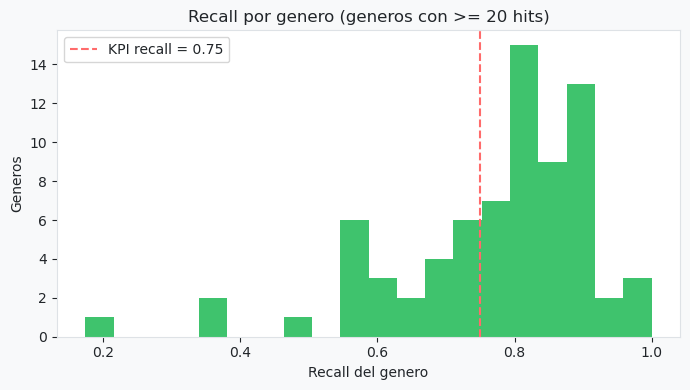

[graficos] Guardado: output\graficos\13_recall_por_genero.png


In [10]:
gr.grafico_recall_por_genero(elegibles)

### 4b. Recall por género sin filtrar: umbral 0.5 frente a la política oficial
La tabla anterior solo incluye géneros con 20 o más hits, lo que excluye a los de pocos hits (los más difíciles). Aquí se usan **todos** los géneros con al menos un hit y se agrupan por hit rate del género, con el umbral 0.5 y con la política oficial. El recall "global" cuenta cada canción una vez por cada género al que pertenece, por eso difiere levemente del recall del modelo.

In [11]:
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def recall_genero(pred):
    d = (raw_test[["track_genre"]].assign(y=y_test.values, pred=pred)
         .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
    d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)
    g = d.groupby("genero").agg(n=("y", "size"), hits=("y", "sum"), marcados=("pred", "sum"), tp=("tp", "sum"))
    g["hit_rate_genero"] = g.hits / g.n
    g["recall"] = g.tp / g.hits.where(g.hits > 0)
    g["precision"] = g.tp / g.marcados.where(g.marcados > 0)
    return g

def tramos_genero(g):
    con = g[g.hits > 0]
    tr = pd.cut(con.hit_rate_genero, [0, 0.10, 0.25, 0.50, 1.0], include_lowest=True,
                labels=["bajo (<10%)", "medio (10-25%)", "alto (25-50%)", "muy alto (>50%)"])
    t = con.groupby(tr, observed=True).agg(generos=("n", "size"), hits=("hits", "sum"), tp=("tp", "sum"),
                                           marcados=("marcados", "sum"), n=("n", "sum"))
    return pd.DataFrame({"generos": t.generos, "hits": t.hits, "recall": t.tp / t.hits,
                         "precision": t.tp / t.marcados, "% marcadas": t.marcados / t.n * 100})

resumen_g = {}
for nombre_p, pred_ in (("umbral 0.5", (p >= 0.5).astype(int)), ("oficial", pred_of)):
    g = recall_genero(pred_); con_hits = g[g.hits > 0]
    rho, _ = spearmanr(con_hits.hit_rate_genero, con_hits.recall)
    resumen_g[nombre_p] = {"recall macro (géneros)": con_hits.recall.mean(),
                           "géneros con recall < 0.75": (con_hits.recall < 0.75).sum(),
                           "% géneros con recall < 0.75": (con_hits.recall < 0.75).mean() * 100,
                           "Spearman (hit rate del género, recall)": rho}
    if nombre_p == "oficial":
        g_of, con_hits_of = g, con_hits
    else:
        g_05 = g
print(f"Géneros con al menos 1 hit en test: {len(con_hits_of)} de {len(g_of)}")
display(pd.DataFrame(resumen_g).round(3))
pd.concat({"umbral 0.5": tramos_genero(g_05), "oficial": tramos_genero(g_of)}, axis=1).round(3)

Géneros con al menos 1 hit en test: 109 de 114


,umbral 0.5,oficial
recall macro (géneros),0.559,0.591
géneros con recall < 0.75,59.000,56.000
% géneros con recall < 0.75,54.128,51.376
"Spearman (hit rate del género, recall)",0.948,0.833


umbral 0.5                                   oficial        \
                   generos  hits recall precision % marcadas generos  hits   
hit_rate_genero                                                              
bajo (<10%)             35   263  0.144     0.242      2.251      35   263   
medio (10-25%)          31  1148  0.594     0.355     30.707      31  1148   
alto (25-50%)           33  2567  0.944     0.432     81.720      33  2567   
muy alto (>50%)         10  1241  0.996     0.667     94.300      10  1241   

                                             
                recall precision % marcadas  
hit_rate_genero                              
bajo (<10%)      0.354     0.171      7.815  
medio (10-25%)   0.700     0.306     42.056  
alto (25-50%)    0.827     0.461     67.128  
muy alto (>50%)  0.886     0.716     78.066

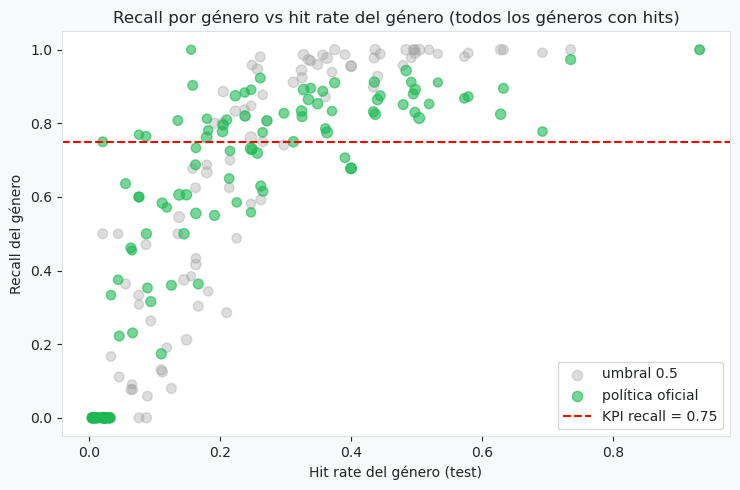

In [12]:
con_05 = g_05[g_05.hits > 0]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(con_05.hit_rate_genero, con_05.recall, s=con_05.n / 4, alpha=0.35, color="#9E9E9E", label="umbral 0.5")
ax.scatter(con_hits_of.hit_rate_genero, con_hits_of.recall, s=con_hits_of.n / 4, alpha=0.6, color="#1DB954", label="política oficial")
ax.axhline(0.75, color="red", ls="--", label="KPI recall = 0.75")
ax.set_xlabel("Hit rate del género (test)"); ax.set_ylabel("Recall del género")
ax.set_title("Recall por género vs hit rate del género (todos los géneros con hits)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "16_recall_vs_hit_rate_genero.png"), dpi=120, bbox_inches="tight"); plt.show()

## 5. Importancia de variables (permutación)
Se permuta cada variable en test y se mide cuánto cae el AUC. Las columnas de género se permutan **juntas, como un solo bloque**: permutarlas una a una no tiene sentido porque cada una es solo un 0/1 de un género.

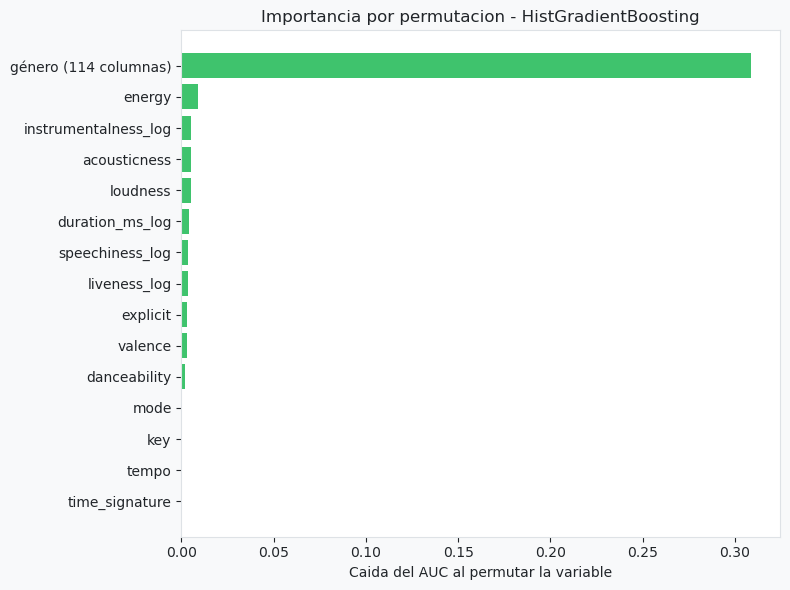

[graficos] Guardado: output\graficos\14_importancia_permutacion.png


,caída AUC
género (114 columnas),0.3090
energy,0.0089
instrumentalness_log,0.0053
acousticness,0.0051
loudness,0.0050


In [13]:
imp = gr.tabla_importancia_permutacion(m, X_test, y_test)
gr.grafico_importancia_permutacion(imp, mejor)
imp.sort_values(ascending=False).head(5).round(4).to_frame("caída AUC")

## 6. K-Means (no supervisado)
Se agrupan las canciones solo por sus variables de audio (sin género ni target) y luego se mira si los clusters se asocian con el hit rate.

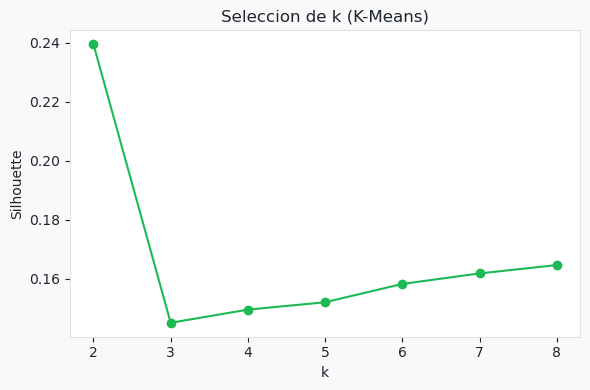

[graficos] Guardado: output\graficos\15_kmeans_silhouette.png
k elegido por silhouette: 2 (silhouette = 0.240)


In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_train[FEATURES_SCALE])
Xk_tr, Xk_te = sc.transform(X_train[FEATURES_SCALE]), sc.transform(X_test[FEATURES_SCALE])

sil = gr.silhouette_kmeans(Xk_tr)
k_opt = gr.grafico_kmeans_silhouette(sil)
print(f"k elegido por silhouette: {k_opt} (silhouette = {sil[k_opt]:.3f})")

In [15]:
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(Xk_tr)
perfil = (X_test[["danceability", "energy", "acousticness", "valence", "loudness"]]
          .assign(cluster=km.predict(Xk_te), hit=y_test.values))
res_km = perfil.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"),
                                       danceability=("danceability", "mean"), energy=("energy", "mean"),
                                       acousticness=("acousticness", "mean"), valence=("valence", "mean"),
                                       loudness=("loudness", "mean")).round(3)
print(f"Hit rate base en test: {y_test.mean():.3f}")
res_km

Hit rate base en test: 0.205


,n,hit_rate,danceability,energy,acousticness,valence,loudness
cluster,,,,,,,
0,4430,0.191,0.462,0.295,0.755,0.313,-14.664
1,13604,0.210,0.595,0.749,0.189,0.521,-6.446


### 6b. Más criterios para elegir k
Silhouette por sí solo tiende a favorecer k = 2 (la partición más gruesa posible). Se agregan el codo (inercia) y Davies-Bouldin, con el mismo escalado y semilla. El silhouette se calcula sobre una muestra fija de 10.000 canciones porque el cálculo exacto es O(n²).

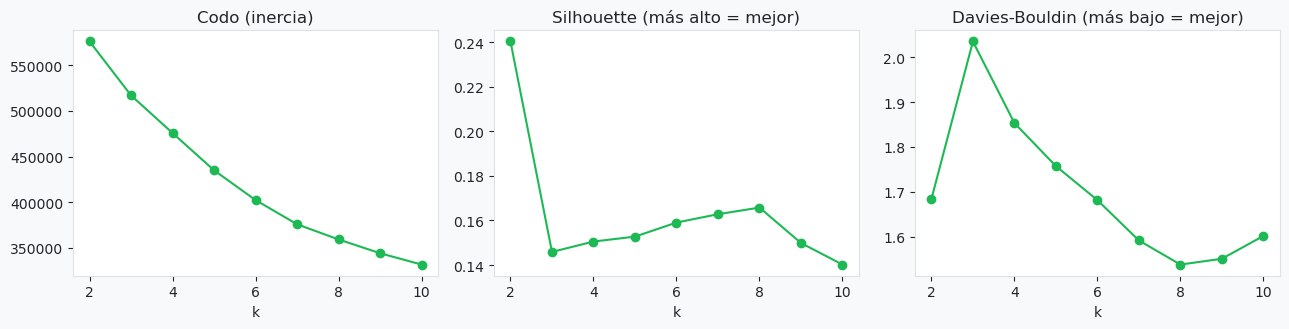

,inercia,silhouette,Davies-Bouldin
k,,,
2,575926.926,0.240,1.684
3,516914.344,0.146,2.035
4,475747.944,0.151,1.853
5,435004.902,0.153,1.757
6,402425.575,0.159,1.681
7,375967.623,0.163,1.591
8,359350.721,0.166,1.537
9,344280.255,0.150,1.550
10,331873.478,0.140,1.601


In [16]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, roc_auc_score
import matplotlib.pyplot as plt

idx_sil = np.random.RandomState(42).choice(len(Xk_tr), 10000, replace=False)   # muestra fija para silhouette
filas_k = []
for k_ in range(2, 11):
    km_k = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr)
    filas_k.append({"k": k_, "inercia": km_k.inertia_,
                    "silhouette": silhouette_score(Xk_tr[idx_sil], km_k.labels_[idx_sil]),
                    "Davies-Bouldin": davies_bouldin_score(Xk_tr, km_k.labels_)})
crit_k = pd.DataFrame(filas_k).set_index("k")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col, tit in zip(ax, ["inercia", "silhouette", "Davies-Bouldin"],
                       ["Codo (inercia)", "Silhouette (más alto = mejor)", "Davies-Bouldin (más bajo = mejor)"]):
    a.plot(crit_k.index, crit_k[col], marker="o", color="#1DB954"); a.set_title(tit); a.set_xlabel("k")
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "17_kmeans_criterios_k.png"), dpi=120, bbox_inches="tight"); plt.show()
crit_k.round(3)

### 6c. Estabilidad de los clusters
Se ajusta el mismo K-Means en dos mitades disjuntas de train y se comparan las etiquetas que cada una asigna a test con el índice de Rand ajustado (ARI: 1 = clusters idénticos, 0 = azar). Un cluster que cambia según la muestra no es un patrón.

In [17]:
perm = np.random.RandomState(42).permutation(len(Xk_tr))
mitad_a, mitad_b = perm[: len(perm) // 2], perm[len(perm) // 2:]
filas_est = []
for k_ in range(2, 9):
    la = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr[mitad_a]).predict(Xk_te)
    lb = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr[mitad_b]).predict(Xk_te)
    filas_est.append({"k": k_, "ARI entre mitades": adjusted_rand_score(la, lb)})
est_k = pd.DataFrame(filas_est).set_index("k")
est_k.round(3).T

k,2,3,4,5,6,7,8
ARI entre mitades,0.984,0.962,0.957,0.974,0.978,0.973,0.677


### 6d. Segmentación con k ≥ 3: perfil, géneros y valor predictivo
Con k = 2 solo se separa "tranquilo/acústico" de "enérgico". Para segmentar un catálogo se exige k ≥ 3 y estabilidad (ARI ≥ 0,90 en 6c), y entre los k que cumplen se toma el de mayor silhouette. Se perfilan los clusters con todas las variables de audio (en test y en train), se revisa qué géneros los componen y se mide cuánta señal de hit contienen: el AUC de usar solo el hit rate del cluster.

In [18]:
from IPython.display import display
from sklearn.decomposition import PCA

genre_cols = [c for c in X_train.columns if c.startswith("genre_")]
y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
k_ok = [k_ for k_ in est_k.index if k_ >= 3 and est_k.loc[k_, "ARI entre mitades"] >= 0.90]    # k >= 3 y estable
k_seg = int(crit_k.loc[k_ok, "silhouette"].idxmax())
km_seg = KMeans(n_clusters=k_seg, n_init=10, random_state=42).fit(Xk_tr)
lab_tr, lab_te = km_seg.labels_, km_seg.predict(Xk_te)
print(f"k de segmentación: {k_seg} (silhouette {crit_k.loc[k_seg, 'silhouette']:.3f}) | hit rate base en test: {y_test.mean():.3f}")

def perfil_clusters(X, y, lab):
    d = X[FEATURES_SCALE + ["explicit"]].assign(cluster=lab, hit=np.asarray(y))
    out = d.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"), explicit=("explicit", "mean"),
                                   **{c: (c, "mean") for c in FEATURES_SCALE})
    out.insert(1, "% canciones", out["n"] / out["n"].sum() * 100)
    return out.round(3)

print("\nPerfil de los clusters (test):"); display(perfil_clusters(X_test, y_test, lab_te))
print("Perfil de los clusters (train):"); display(perfil_clusters(X_train, y_train, lab_tr))

# Géneros más frecuentes dentro de cada cluster (test)
G_te_f = X_test[genre_cols].values.astype(float)
comp = pd.DataFrame(G_te_f, columns=[c.replace("genre_", "") for c in genre_cols]).groupby(lab_te).mean()
top_gen = {f"cluster {c}": ", ".join(f"{g} ({comp.loc[c, g] * 100:.0f}%)" for g in comp.loc[c].nlargest(5).index) for c in comp.index}
display(pd.Series(top_gen, name="5 géneros más frecuentes (% de las canciones del cluster)").to_frame())

# ¿Cuánta señal de hit hay en el cluster de audio?
tasa_cl = pd.Series(np.asarray(y_train)).groupby(lab_tr).mean()
auc_cl = roc_auc_score(y_test, tasa_cl.reindex(lab_te).values)
print(f"AUC en test usando solo el hit rate del cluster de audio (tasas de train): {auc_cl:.3f}  (azar = 0.5; solo género ≈ 0.83; modelo completo ≈ 0.87)")

k de segmentación: 7 (silhouette 0.163) | hit rate base en test: 0.205

Perfil de los clusters (test):


,n,% canciones,hit_rate,explicit,danceability,energy,loudness,valence,tempo,acousticness,speechiness_log,instrumentalness_log,liveness_log,duration_ms_log
cluster,,,,,,,,,,,,,,
0,5102,28.291,0.236,0.110,0.703,0.723,-6.427,0.714,119.414,0.224,0.072,0.018,0.149,12.199
1,870,4.824,0.166,0.437,0.659,0.668,-8.155,0.517,118.664,0.405,0.376,0.025,0.258,12.081
2,1368,7.586,0.176,0.002,0.347,0.174,-21.282,0.184,103.457,0.858,0.049,0.555,0.149,12.116
3,3414,18.931,0.231,0.033,0.531,0.370,-10.647,0.398,113.579,0.694,0.048,0.029,0.144,12.201
4,3893,21.587,0.244,0.086,0.467,0.816,-5.322,0.365,139.485,0.073,0.073,0.028,0.172,12.342
5,2003,11.107,0.101,0.040,0.581,0.749,-8.459,0.336,127.014,0.100,0.066,0.568,0.151,12.488
6,1384,7.674,0.125,0.061,0.510,0.759,-6.971,0.491,123.353,0.276,0.076,0.059,0.531,12.311


Perfil de los clusters (train):


,n,% canciones,hit_rate,explicit,danceability,energy,loudness,valence,tempo,acousticness,speechiness_log,instrumentalness_log,liveness_log,duration_ms_log
cluster,,,,,,,,,,,,,,
0,20106,28.039,0.244,0.105,0.702,0.721,-6.480,0.710,118.463,0.217,0.070,0.018,0.144,12.206
1,3412,4.758,0.171,0.407,0.657,0.653,-8.457,0.517,116.565,0.412,0.381,0.022,0.262,12.089
2,5343,7.451,0.169,0.003,0.342,0.172,-21.179,0.182,102.006,0.858,0.049,0.562,0.145,12.110
3,13991,19.512,0.226,0.035,0.527,0.372,-10.652,0.393,113.039,0.694,0.046,0.033,0.144,12.223
4,15328,21.376,0.250,0.101,0.471,0.809,-5.412,0.366,139.130,0.079,0.074,0.029,0.169,12.339
5,8154,11.371,0.111,0.036,0.583,0.750,-8.398,0.340,127.616,0.095,0.066,0.569,0.150,12.487
6,5372,7.492,0.143,0.058,0.521,0.757,-6.939,0.513,123.664,0.281,0.075,0.058,0.535,12.300


,5 géneros más frecuentes (% de las canciones del cluster)
cluster 0,"hip-hop (3%), reggaeton (3%), latino (3%), lat..."
cluster 1,"comedy (19%), j-dance (10%), dancehall (7%), f..."
cluster 2,"new-age (12%), sleep (12%), ambient (10%), cla..."
cluster 3,"singer-songwriter (4%), songwriter (4%), tango..."
cluster 4,"metalcore (5%), metal (4%), dubstep (4%), heav..."
cluster 5,"minimal-techno (9%), detroit-techno (8%), tech..."
cluster 6,"pagode (8%), sertanejo (7%), samba (6%), mpb (..."


AUC en test usando solo el hit rate del cluster de audio (tasas de train): 0.576  (azar = 0.5; solo género ≈ 0.83; modelo completo ≈ 0.87)


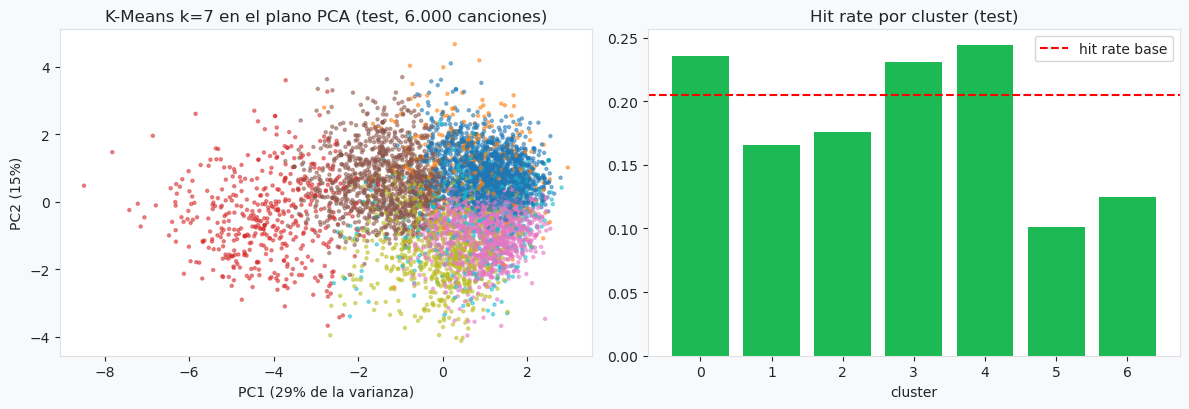

In [19]:
pca = PCA(n_components=2, random_state=42).fit(Xk_tr)
Z = pca.transform(Xk_te)
muestra = np.random.RandomState(42).choice(len(Z), 6000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(Z[muestra, 0], Z[muestra, 1], c=lab_te[muestra], cmap="tab10", s=5, alpha=0.5)
ax[0].set_title(f"K-Means k={k_seg} en el plano PCA (test, 6.000 canciones)")
ax[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}% de la varianza)")
ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}%)")
hr = pd.Series(np.asarray(y_test)).groupby(lab_te).mean()
ax[1].bar(hr.index.astype(str), hr.values, color="#1DB954")
ax[1].axhline(np.mean(y_test), color="red", ls="--", label="hit rate base")
ax[1].set_title("Hit rate por cluster (test)"); ax[1].set_xlabel("cluster"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "18_kmeans_pca_clusters.png"), dpi=120, bbox_inches="tight"); plt.show()

### 6e. Segmentación de géneros por su perfil de audio (dos técnicas)
El hit lo explica sobre todo el género, así que la pregunta de negocio más útil es otra: **¿qué tipos de género existen según cómo suenan y cómo se comporta su popularidad?** Cada género (114) se describe por el audio medio de sus canciones en train (estandarizado). Se agrupan con K-Means y con clustering jerárquico (Ward) y se mide su acuerdo con el ARI. El hit rate **no** entra al clustering; se usa después para interpretar los grupos. Luego se cruza con el recall del modelo en test.

In [20]:
from sklearn.cluster import AgglomerativeClustering
from scipy.stats import spearmanr

nombres_gen = [c.replace("genre_", "") for c in genre_cols]
G_tr_f = X_train[genre_cols].values.astype(float)
n_gen_tr = np.maximum(G_tr_f.sum(axis=0), 1)
perfil_gen = pd.DataFrame((G_tr_f.T @ Xk_tr) / n_gen_tr[:, None], index=nombres_gen, columns=FEATURES_SCALE)   # audio medio por género
hit_gen_tr = pd.Series((G_tr_f.T @ np.asarray(y_train, dtype=float)) / n_gen_tr, index=nombres_gen)

sil_gen = {k_: silhouette_score(perfil_gen, KMeans(n_clusters=k_, n_init=20, random_state=42).fit_predict(perfil_gen)) for k_ in range(2, 9)}
k_gen = max((k_ for k_ in sil_gen if k_ >= 3), key=sil_gen.get)           # k >= 3, mayor silhouette
print("Silhouette por k (géneros):", {k_: round(v, 3) for k_, v in sil_gen.items()})
km_gen = KMeans(n_clusters=k_gen, n_init=20, random_state=42).fit(perfil_gen)
lab_gen = km_gen.labels_
lab_ward = AgglomerativeClustering(n_clusters=k_gen, linkage="ward").fit_predict(perfil_gen)
print(f"k elegido = {k_gen} | acuerdo K-Means vs jerárquico (ARI) = {adjusted_rand_score(lab_gen, lab_ward):.3f}")

# Cruce con el hit rate (train y test) y con el recall del modelo oficial (política de umbral, test)
y_te_f = np.asarray(y_test, dtype=float)
hits_g = G_te_f.T @ y_te_f
tp_g = G_te_f.T @ (y_te_f * pred_of)
tabla_g = pd.DataFrame({"cluster": lab_gen, "hit_rate_train": hit_gen_tr.values,
                        "hit_rate_test": hits_g / np.maximum(G_te_f.sum(axis=0), 1),
                        "hits_test": hits_g, "tp_test": tp_g}, index=nombres_gen)
resumen_gen = tabla_g.groupby("cluster").agg(generos=("hit_rate_train", "size"), hit_rate_medio=("hit_rate_train", "mean"),
                                             hit_rate_min=("hit_rate_train", "min"), hit_rate_max=("hit_rate_train", "max"),
                                             hits_test=("hits_test", "sum"), tp_test=("tp_test", "sum"))
resumen_gen["recall (oficial)"] = resumen_gen.tp_test / resumen_gen.hits_test
resumen_gen = resumen_gen.drop(columns=["hits_test", "tp_test"]).join(
    perfil_gen.groupby(lab_gen)[["acousticness", "energy", "danceability", "instrumentalness_log", "speechiness_log"]].mean())
cerca = pd.DataFrame(km_gen.transform(perfil_gen), index=nombres_gen)
resumen_gen["géneros más típicos"] = [", ".join(cerca[tabla_g.cluster.values == c][c].nsmallest(4).index) for c in resumen_gen.index]
display(resumen_gen.round(3))

corr_gen = pd.Series({c: spearmanr(perfil_gen[c], hit_gen_tr)[0] for c in FEATURES_SCALE}).sort_values()
print("Spearman entre el audio medio del género y su hit rate (114 géneros):")
display(corr_gen.round(2).to_frame("rho").T)

Silhouette por k (géneros): {2: 0.347, 3: 0.241, 4: 0.239, 5: 0.214, 6: 0.24, 7: 0.226, 8: 0.22}
k elegido = 3 | acuerdo K-Means vs jerárquico (ARI) = 0.471


,generos,hit_rate_medio,hit_rate_min,hit_rate_max,recall (oficial),acousticness,energy,danceability,instrumentalness_log,speechiness_log,géneros más típicos
cluster,,,,,,,,,,,
0,59,0.245,0.0,0.653,0.787,-0.583,0.521,0.145,-0.046,0.018,"groove, dub, alternative, alt-rock"
1,12,0.119,0.0,0.465,0.742,1.088,-1.149,-0.833,1.098,-0.236,"piano, ambient, guitar, disney"
2,43,0.246,0.0,0.945,0.799,0.384,-0.325,0.105,-0.386,-0.021,"soul, indie, indie-pop, indian"


Spearman entre el audio medio del género y su hit rate (114 géneros):


,liveness_log,instrumentalness_log,speechiness_log,duration_ms_log,acousticness,valence,energy,tempo,danceability,loudness
rho,-0.3,-0.13,-0.1,-0.1,-0.07,-0.07,-0.02,-0.01,0.1,0.15


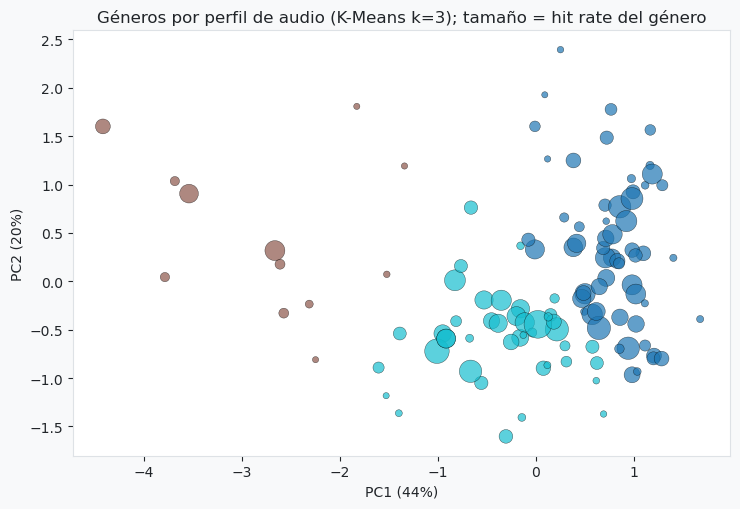

In [21]:
pg = PCA(n_components=2, random_state=42).fit(perfil_gen)
Zg = pg.transform(perfil_gen)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sc_g = ax.scatter(Zg[:, 0], Zg[:, 1], c=lab_gen, cmap="tab10", s=20 + 400 * hit_gen_tr.values, alpha=0.7, edgecolor="k", linewidth=0.3)
ax.set_title(f"Géneros por perfil de audio (K-Means k={k_gen}); tamaño = hit rate del género")
ax.set_xlabel(f"PC1 ({pg.explained_variance_ratio_[0] * 100:.0f}%)"); ax.set_ylabel(f"PC2 ({pg.explained_variance_ratio_[1] * 100:.0f}%)")
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "19_kmeans_generos.png"), dpi=120, bbox_inches="tight"); plt.show()

### Lectura del K-Means ampliado
- **Elección de k.** El silhouette más alto es k = 2 (0,240), pero solo separa tranquilo de enérgico. Desde k = 3 los valores son bajos y parecidos (0,14 a 0,17): el audio no tiene una estructura de grupos nítida. La estabilidad es alta hasta k = 7 (ARI ≥ 0,957) y cae en k = 8 (0,677), por eso se segmenta con **k = 7**, y los perfiles de train y test casi coinciden.
- **Los clusters son familias de estilo, no niveles de popularidad.** Se reconocen grupos como ambient/sleep/clásica, techno instrumental, metal y dubstep, música brasileña en vivo, comedia y habla explícita, pop urbano bailable y cantautor acústico.
- **La señal de hit es débil.** Los hit rate van de ≈ 0,10 a ≈ 0,24 (base 0,205). Los grupos claramente bajos son el techno instrumental (≈ 0,10) y la música en vivo (≈ 0,13); el resto está entre 0,17 y 0,24. Usar solo el cluster de audio da un AUC de **0,576**, frente a ≈ 0,83 del género y ≈ 0,87 del modelo.
- **Segmentos de géneros (k = 3).** El silhouette favorece k = 2 (0,347), pero se exige k ≥ 3 (0,241). El acuerdo entre K-Means y Ward es moderado (ARI 0,47), así que estos grupos no son muy robustos. Un grupo pequeño de 12 géneros (piano, ambient, guitar, disney: acústicos, instrumentales y de baja energía) tiene hit rate medio 0,12 frente a 0,245 de los otros dos, y el modelo lo detecta algo peor (recall con la política oficial 0,74 frente a 0,79 y 0,80). Dentro de cada grupo hay géneros con hit rate 0 y, en los dos grupos grandes, otros de 0,65 a 0,95: el perfil de audio de un género no determina su popularidad. La variable de audio más asociada al hit rate del género es `liveness` (Spearman −0,30).
- **Uso de negocio:** el no supervisado sirve para segmentar el catálogo por estilo y adaptar campañas; no sustituye la información de género ni predice popularidad por sí solo.

## 7. Sensibilidad: split agrupado por artista
El split del pipeline agrupa por canción, y casi todo el test contiene artistas ya vistos en train. Aquí se re-divide train+test agrupando por **artista principal** (primer artista de la cadena), recalculando el P80 solo con el nuevo train, y se compara con la agrupación actual usando 3 semillas y los hiperparámetros del mejor modelo. Una colaboración puede seguir conectando artistas, por eso se reporta el % de test con artista visto.

In [22]:
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

# Pool = train + test originales (mismo orden que X_train / X_test); se re-divide con distintos criterios de agrupación
raw_train = pd.read_csv("data/raw/train/raw_train.csv")
pool_raw = pd.concat([raw_train, raw_test], ignore_index=True)
X_pool = pd.concat([X_train, X_test], ignore_index=True)
assert len(pool_raw) == len(X_pool)

pool_raw["artista_principal"] = pool_raw["artists"].str.split(";").str[0].str.strip().str.lower()

def solape_artistas(raw_tr, raw_te):
    """% de canciones de test con al menos un artista individual presente en train."""
    en_train = set(raw_tr["artists"].str.lower().str.split(";").explode().str.strip())
    return raw_te["artists"].str.lower().str.split(";").apply(lambda l: any(a.strip() in en_train for a in l)).mean()

def evaluar_split(grupos, semilla):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semilla)
    i_tr, i_te = next(gss.split(X_pool, groups=grupos))
    umbral_tr = pool_raw["popularity"].iloc[i_tr].quantile(0.80)             # P80 solo con el nuevo train
    y_all = (pool_raw["popularity"] >= umbral_tr).astype(int)
    mod = clone(modelos[mejor]).fit(X_pool.iloc[i_tr], y_all.iloc[i_tr])      # mismos hiperparámetros del mejor modelo
    p_s = mod.predict_proba(X_pool.iloc[i_te])[:, 1]
    yt, pred_s = y_all.iloc[i_te], (p_s >= 0.5).astype(int)
    k = int(len(yt) * 0.10)
    return {"AUC": roc_auc_score(yt, p_s), "PR-AUC": average_precision_score(yt, p_s),
            "Recall": recall_score(yt, pred_s), "Precision": precision_score(yt, pred_s),
            "Lift@10%": yt.values[np.argsort(-p_s)[:k]].mean() / yt.mean(),
            "% test con artista visto": solape_artistas(pool_raw.iloc[i_tr], pool_raw.iloc[i_te]) * 100}

filas = []
for semilla in (42, 43, 44):
    for nombre, grupos in (("Por canción (actual)", pool_raw["song_key"]),
                           ("Por artista principal", pool_raw["artista_principal"])):
        filas.append({"Agrupación": nombre, "semilla": semilla, **evaluar_split(grupos, semilla)})
sens = pd.DataFrame(filas)
print(f"Modelo evaluado: {mejor} | 3 semillas por criterio")
sens.drop(columns="semilla").groupby("Agrupación").agg(["mean", "std"]).round(4)

Modelo evaluado: HistGradientBoosting | 3 semillas por criterio


AUC          PR-AUC          Recall          \
                         mean     std    mean     std    mean     std   
Agrupación                                                              
Por artista principal  0.8584  0.0046  0.6315  0.0132  0.7958  0.0211   
Por canción (actual)   0.8662  0.0039  0.6383  0.0105  0.8220  0.0108   

                      Precision         Lift@10%          \
                           mean     std     mean     std   
Agrupación                                                 
Por artista principal    0.4677  0.0058   3.3485  0.0572   
Por canción (actual)     0.4600  0.0034   3.4307  0.0141   

                      % test con artista visto          
                                          mean     std  
Agrupación                                              
Por artista principal                  36.2673  2.0626  
Por canción (actual)                   91.6397  0.0753

## 8. Sensibilidad: excluir popularidad 0
La popularidad 0 se concentra en ciertos géneros y artistas y hoy cuenta como "no hit". Aquí se excluye de train **y** test, se recalcula el P80 solo con train y se compara con el escenario actual, con y sin las columnas de género (ablación: se anulan las columnas `genre_*`). Los dos escenarios usan conjuntos de test distintos y definiciones de hit distintas, por lo que los AUC no son estrictamente comparables; lo que importa es si el aporte del género cambia.

In [23]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

genre_cols = [c for c in X_train.columns if c.startswith("genre_")]
y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
raw_train = pd.read_csv("data/raw/train/raw_train.csv")

def sin_genero(X):
    """Ablación: se anulan las columnas de género (el modelo solo puede usar audio, metadatos y texto)."""
    X = X.copy(); X[genre_cols] = 0
    return X

def ajustar_evaluar(Xtr, ytr, Xte, yte):
    mod = clone(modelos[mejor]).fit(Xtr, ytr)                 # mismos hiperparámetros del mejor modelo
    p_ = mod.predict_proba(Xte)[:, 1]
    pred_ = (p_ >= 0.5).astype(int)
    k = int(len(yte) * 0.10)
    return {"n test": len(yte), "hit rate test": float(np.mean(yte)),
            "AUC": roc_auc_score(yte, p_), "PR-AUC": average_precision_score(yte, p_),
            "Recall": recall_score(yte, pred_), "Precision": precision_score(yte, pred_),
            "Lift@10%": np.asarray(yte)[np.argsort(-p_)[:k]].mean() / np.mean(yte)}

# Escenario sin popularidad 0: se excluye de train Y de test y el P80 se recalcula solo con train
mask_tr = (raw_train["popularity"] > 0).values
mask_te = (raw_test["popularity"] > 0).values
print(f"Canciones con popularidad 0 excluidas -> train: {(~mask_tr).mean()*100:.1f}% | test: {(~mask_te).mean()*100:.1f}%")
umbral0 = raw_train.loc[mask_tr, "popularity"].quantile(0.80)
print(f"P80 sin popularidad 0 (train): {umbral0} (con popularidad 0: 52.0)")
y_tr0 = (raw_train.loc[mask_tr, "popularity"] >= umbral0).astype(int).values
y_te0 = (raw_test.loc[mask_te, "popularity"] >= umbral0).astype(int).values
Xtr0, Xte0 = X_train[mask_tr], X_test[mask_te]

filas = {
    "Actual (pop 0 = no hit) | con género":  ajustar_evaluar(X_train, y_train, X_test, y_test),
    "Actual (pop 0 = no hit) | solo audio":  ajustar_evaluar(sin_genero(X_train), y_train, sin_genero(X_test), y_test),
    "Sin popularidad 0       | con género":  ajustar_evaluar(Xtr0, y_tr0, Xte0, y_te0),
    "Sin popularidad 0       | solo audio":  ajustar_evaluar(sin_genero(Xtr0), y_tr0, sin_genero(Xte0), y_te0),
}
tabla_pop0 = pd.DataFrame(filas).T.round(4)
print(f"Aporte del género (AUC con género - solo audio): actual {tabla_pop0.iloc[0].AUC - tabla_pop0.iloc[1].AUC:+.3f} | "
      f"sin popularidad 0 {tabla_pop0.iloc[2].AUC - tabla_pop0.iloc[3].AUC:+.3f}")
tabla_pop0

Canciones con popularidad 0 excluidas -> train: 10.3% | test: 11.0%
P80 sin popularidad 0 (train): 54.0 (con popularidad 0: 52.0)
Aporte del género (AUC con género - solo audio): actual +0.155 | sin popularidad 0 +0.161


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Actual (pop 0 = no hit) | con género,18034.0,0.2053,0.8663,0.6337,0.8244,0.4577,3.4313
Actual (pop 0 = no hit) | solo audio,18034.0,0.2053,0.7115,0.3836,0.6788,0.3207,2.1318
Sin popularidad 0 | con género,16051.0,0.2024,0.8907,0.6821,0.8454,0.4917,3.7164
Sin popularidad 0 | solo audio,16051.0,0.2024,0.7298,0.3993,0.6955,0.3249,2.3308


## 9. Sensibilidad: target relativo al género
Si el género casi determina el hit, queda la duda de si el audio predice algo **dentro** de cada género. Aquí el hit se redefine como popularidad ≥ P80 **del género** (umbrales calculados solo con train; una canción con varios géneros usa el promedio de los umbrales de sus géneros). Con esta definición el hit rate es ≈ 20% en todos los géneros, así que el género deja de ser un predictor "gratis". Es un problema de negocio distinto ("¿será hit dentro de su género?") y se usa solo como prueba de sensibilidad. En géneros con muchos ceros el umbral es muy bajo, lo que vuelve ruidosa la etiqueta ahí.

In [24]:
from scipy.stats import spearmanr

gtr = raw_train[["track_genre", "popularity"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
umbral_genero = gtr.groupby("genero")["popularity"].quantile(0.80)
umbral_global = raw_train["popularity"].quantile(0.80)

def umbral_cancion(raw):
    e = raw[["track_genre"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
    e["u"] = e["genero"].map(umbral_genero).fillna(umbral_global)          # género no visto -> umbral global
    return e.groupby(level=0)["u"].mean().reindex(raw.index).values

y_tr_rel = (raw_train["popularity"].values >= umbral_cancion(raw_train)).astype(int)
y_te_rel = (raw_test["popularity"].values >= umbral_cancion(raw_test)).astype(int)
print(f"Hit rate con target relativo -> train: {y_tr_rel.mean():.3f} | test: {y_te_rel.mean():.3f}")
print(f"Umbral P80 por género: mínimo {umbral_genero.min():.0f}, mediana {umbral_genero.median():.0f}, máximo {umbral_genero.max():.0f}")

res_rel = {
    "Target relativo | con género": ajustar_evaluar(X_train, y_tr_rel, X_test, y_te_rel),
    "Target relativo | solo audio": ajustar_evaluar(sin_genero(X_train), y_tr_rel, sin_genero(X_test), y_te_rel),
}
tabla_rel = pd.DataFrame(res_rel).T.round(4)
print(f"Aporte del género con target relativo (AUC con género - solo audio): {tabla_rel.iloc[0].AUC - tabla_rel.iloc[1].AUC:+.3f}")
tabla_rel

Hit rate con target relativo -> train: 0.198 | test: 0.198
Umbral P80 por género: mínimo 3, mediana 51, máximo 75
Aporte del género con target relativo (AUC con género - solo audio): +0.069


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Target relativo | con género,18034.0,0.1981,0.6654,0.3433,0.6039,0.2860,2.0049
Target relativo | solo audio,18034.0,0.1981,0.5968,0.2785,0.5524,0.2452,1.5737


In [25]:
# ¿Se parejó el recall entre géneros? (modelo con género, target relativo, umbral 0.5)
mod_rel = clone(modelos[mejor]).fit(X_train, y_tr_rel)
pred_rel = (mod_rel.predict_proba(X_test)[:, 1] >= 0.5).astype(int)

def recall_por_genero(raw, y, pred):
    d = (raw[["track_genre"]].assign(y=np.asarray(y), pred=pred)
         .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
    d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)
    g = d.groupby("genero").agg(hits=("y", "sum"), tp=("tp", "sum"), n=("y", "size"), marcados=("pred", "sum"))
    g = g[g.hits > 0]
    g["recall"] = g.tp / g.hits
    g["hit_rate_genero"] = g.hits / g.n
    return g

g_abs = recall_por_genero(raw_test, y_test, (p >= 0.5).astype(int))   # target absoluto (modelo original)
g_rel = recall_por_genero(raw_test, y_te_rel, pred_rel)               # target relativo al género
comp = pd.DataFrame({
    "géneros con hits": [len(g_abs), len(g_rel)],
    "recall macro": [g_abs.recall.mean(), g_rel.recall.mean()],
    "desv. estándar del recall entre géneros": [g_abs.recall.std(), g_rel.recall.std()],
    "% géneros con recall < 0.75": [(g_abs.recall < 0.75).mean() * 100, (g_rel.recall < 0.75).mean() * 100],
    "Spearman (hit rate del género, recall)": [spearmanr(g_abs.hit_rate_genero, g_abs.recall)[0],
                                               spearmanr(g_rel.hit_rate_genero, g_rel.recall)[0]],
}, index=["Target absoluto (actual)", "Target relativo al género"]).round(3)
comp

,géneros con hits,recall macro,desv. estándar del recall entre géneros,% géneros con recall < 0.75,"Spearman (hit rate del género, recall)"
Target absoluto (actual),109,0.559,0.398,54.128,0.948
Target relativo al género,114,0.606,0.170,77.193,0.210


## 10. Política de umbral oficial (calibrada sin mirar test)
La sección 2 muestra el efecto del umbral directamente sobre test; eso sirve para describir, **no** para elegir. Aquí todo se calibra con probabilidades **fuera de muestra de train** (CV agrupada de 5 folds, las mismas que guarda `src/train.py` en `prob_oof_train.csv`) y test se usa una sola vez para reportar. Primero, umbrales únicos.

In [26]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
g_train = pd.read_csv("data/processed/train/g_train.csv").squeeze()
genre_cols = [c for c in X_train.columns if c.startswith("genre_")]

# Probabilidades FUERA DE MUESTRA en train: las mismas con que src/train.py calibró la política oficial
oof = pd.read_csv(os.path.join(RESULTADOS_DIR, "prob_oof_train.csv"))["prob_oof"].values
print(f"AUC fuera de muestra en train: {roc_auc_score(y_train, oof):.4f}")

def metricas_umbral(y, prob, u):
    pred = (prob >= u).astype(int)
    return {"umbral": round(float(u), 3), "Precisión": precision_score(y, pred), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "% marcadas": pred.mean() * 100}

malla_u = np.round(np.arange(0.20, 0.86, 0.01), 2)
f1_oof = np.array([f1_score(y_train, (oof >= u).astype(int)) for u in malla_u])
u_f1 = malla_u[f1_oof.argmax()]                                    # máximo F1 en train (fuera de muestra)
u_rec = np.quantile(oof[np.asarray(y_train) == 1], 1 - 0.78)       # recall 0.78 en train (margen sobre el KPI de 0.75)
f1_te = np.array([f1_score(y_test, (p >= u).astype(int)) for u in malla_u])
print(f"Umbral que maximiza F1 en train (OOF): {u_f1:.2f} | mejor umbral mirando test (solo referencia): {malla_u[f1_te.argmax()]:.2f}")
pd.DataFrame({"0.5": metricas_umbral(y_test, p, 0.5),
              "Máx. F1 (calibrado en train)": metricas_umbral(y_test, p, u_f1),
              "Recall 0.78 (calibrado en train)": metricas_umbral(y_test, p, u_rec)}).T.round(3)

AUC fuera de muestra en train: 0.8678
Umbral que maximiza F1 en train (OOF): 0.58 | mejor umbral mirando test (solo referencia): 0.60


,umbral,Precisión,Recall,F1,% marcadas
0.5,0.500,0.458,0.824,0.589,36.975
Máx. F1 (calibrado en train),0.580,0.509,0.737,0.602,29.716
Recall 0.78 (calibrado en train),0.537,0.483,0.786,0.598,33.404


### 10b. Política oficial: umbral por género + corrección por número de géneros
Un umbral único deja el recall muy desigual entre géneros (sección 4b) y marca de más a las canciones con 3 o más géneros (sección 12). La política oficial (`src/metricas.py`) tiene dos pasos:

1. **Umbral por género:** cada género recibe el umbral que logra recall 0,78 sobre sus propios hits (fuera de muestra). Si el género tiene pocos hits, su umbral se **encoge hacia el umbral global**: `u = a·u_género + (1 − a)·u_global`, con `a = hits / (hits + 30)`. Una canción con varios géneros usa el promedio de los umbrales de sus géneros.
2. **Corrección por número de géneros (1, 2, 3+):** un desplazamiento por grupo para que el recall fuera de muestra de cada grupo sea 0,78.

Los dos parámetros (recall objetivo 0,78 y encogimiento 30) son decisiones de diseño, no resultado de una búsqueda: 0,78 da margen sobre el KPI de 0,75 y 30 es el mínimo de hits que usaba la primera versión de esta sección. Los umbrales de cada género y de cada grupo se calculan solo con probabilidades fuera de muestra de train, pero no se puede asegurar que la elección de 0,78 y 30 se hiciera sin haber visto antes resultados de test. No se exploró la sensibilidad de la política a estos dos valores, por lo que no se afirma que sea robusta a ellos.

Se compara con alternativas, todas calibradas con las mismas probabilidades fuera de muestra:
- **Solo por género** (paso 1 sin el 2) y **solo por número de géneros** (paso 2 sin el 1).
- **Equidad fuerte:** umbral por género sin encogimiento y recall objetivo 0,82. Reparte el recall casi por igual entre géneros, pero marca mucho más.

In [27]:
from IPython.display import display

G_tr_b = X_train[genre_cols].values.astype(bool)
G_te_b = X_test[genre_cols].values.astype(bool)
y_tr_a, y_te_a = np.asarray(y_train).astype(int), np.asarray(y_test).astype(int)

pol_of = ajustar_politica(oof, y_tr_a, G_tr_b)                       # = la de src/train.py
assert np.allclose(pol_of["u_genero"], politica["u_genero"]), "la política no coincide con la guardada por train.py"
pol_fuerte = ajustar_politica(oof, y_tr_a, G_tr_b, r_obj=0.82, k=0)
pol_solo_gen = dict(pol_of, ajuste_n={1: 0.0, 2: 0.0, 3: 0.0})
pol_solo_n = ajustar_politica(oof, y_tr_a, G_tr_b, k=np.inf)          # k infinito = mismo umbral global en todos los géneros

def metricas_politica(y, pred, G):
    r = resumen_equidad(y, pred, G)
    return {"Recall global": recall_score(y, pred), "Precisión": precision_score(y, pred), "F1": f1_score(y, pred),
            "% marcadas": pred.mean() * 100, "Recall macro (géneros)": r["recall_macro_generos"],
            "Recall géneros con hit rate < 10%": r["recall_generos_hit_rate_bajo_10pct"],
            "% géneros con recall >= 0.75": r["pct_generos_recall_kpi"],
            "Marcadas / hit rate (1 género)": r["marcadas_sobre_hit_rate_1"],
            "Marcadas / hit rate (2 géneros)": r["marcadas_sobre_hit_rate_2"],
            "Marcadas / hit rate (3+ géneros)": r["marcadas_sobre_hit_rate_3+"]}

pred_05 = (p >= 0.5).astype(int)
pred_fuerte = aplicar_politica(p, G_te_b, pol_fuerte)
politicas_10 = {"Umbral 0.5": pred_05,
                "Solo por n° de géneros": aplicar_politica(p, G_te_b, pol_solo_n),
                "Solo por género": aplicar_politica(p, G_te_b, pol_solo_gen),
                "Oficial (género + n° de géneros)": pred_of,
                "Equidad fuerte (alternativa)": pred_fuerte}
tabla_pol = pd.DataFrame({k_: metricas_politica(y_te_a, v, G_te_b) for k_, v in politicas_10.items()}).T
tabla_pol.round(3)

,Recall global,Precisión,F1,% marcadas,Recall macro (géneros),Recall géneros con hit rate < 10%,% géneros con recall >= 0.75,Marcadas / hit rate (1 género),Marcadas / hit rate (2 géneros),Marcadas / hit rate (3+ géneros)
Umbral 0.5,0.824,0.458,0.589,36.975,0.559,0.144,45.872,1.822,1.590,2.177
Solo por n° de géneros,0.787,0.480,0.596,33.675,0.502,0.114,40.367,1.721,1.339,1.736
Solo por género,0.778,0.433,0.556,36.886,0.600,0.350,49.541,1.833,1.616,1.960
Oficial (género + n° de géneros),0.791,0.423,0.551,38.361,0.591,0.354,48.624,2.016,1.430,1.736
Equidad fuerte (alternativa),0.833,0.285,0.425,59.937,0.771,0.711,71.560,3.417,1.676,1.863


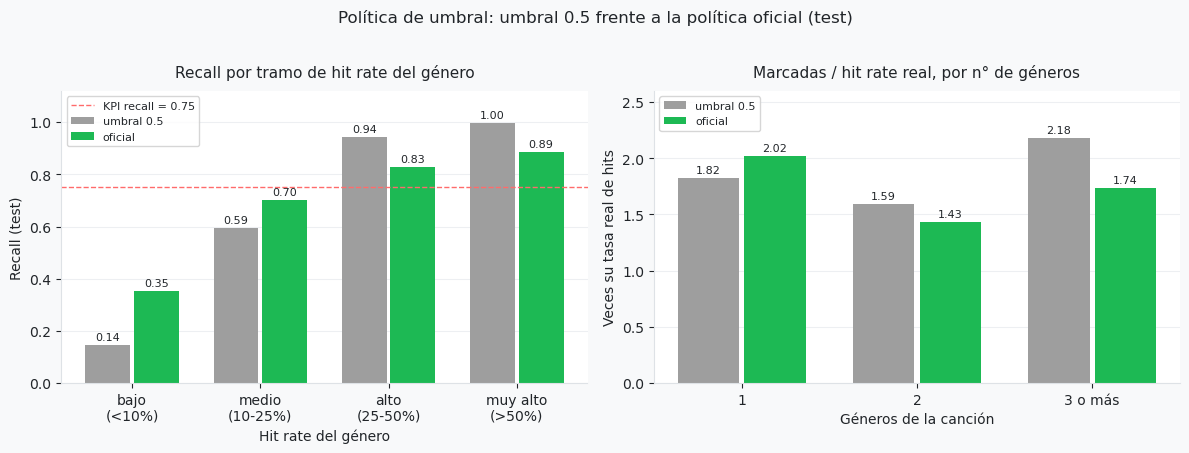

[graficos] Guardado: output\graficos\20_politica_umbral.png


In [28]:
# Evidencia gráfica (20_politica_umbral.png): recall por tramo de hit rate del género y sobre-marcado por n° de géneros
recall_tramos = pd.DataFrame({"umbral 0.5": tramos_genero(g_05)["recall"], "oficial": tramos_genero(g_of)["recall"]})
recall_tramos.index = ["bajo\n(<10%)", "medio\n(10-25%)", "alto\n(25-50%)", "muy alto\n(>50%)"]
marcadas_n = pd.DataFrame({"umbral 0.5": [tabla_pol.loc["Umbral 0.5", f"Marcadas / hit rate ({e})"] for e in ("1 género", "2 géneros", "3+ géneros")],
                           "oficial": [tabla_pol.loc["Oficial (género + n° de géneros)", f"Marcadas / hit rate ({e})"] for e in ("1 género", "2 géneros", "3+ géneros")]},
                          index=["1", "2", "3 o más"])
gr.grafico_politica_umbral(recall_tramos, marcadas_n)


### 10c. ¿Las diferencias superan el ruido? (bootstrap)
Los géneros de hit rate bajo tienen pocos hits en test (≈ 7 por género), así que sus recalls son muy variables. Se remuestrean las canciones de test (300 réplicas, mismas réplicas para las tres políticas) y se reportan intervalos del 95%, incluida la **diferencia pareada** frente al umbral 0.5. Los tramos de hit rate se fijan con la estimación puntual de test.

In [29]:
import scipy.sparse as sp
Gs = sp.csr_matrix(G_te_b.astype(float))
n_te = len(y_te_a)
hits0 = Gs.T @ y_te_a
tasa0 = hits0 / np.maximum(np.asarray(Gs.sum(axis=0)).ravel(), 1)
mask_bajo = (hits0 > 0) & (tasa0 < 0.10)                    # tramo fijo (hit rate del género < 10%)

def stats_boot(w, y, pred):
    hits_g, tp_g = Gs.T @ (w * y), Gs.T @ (w * y * pred)
    ok = hits_g > 0
    return {"Recall global": (w * y * pred).sum() / (w * y).sum(),
            "Precisión": (w * y * pred).sum() / (w * pred).sum(),
            "Recall macro (géneros)": (tp_g[ok] / hits_g[ok]).mean(),
            "Recall géneros con hit rate < 10%": tp_g[mask_bajo].sum() / hits_g[mask_bajo].sum()}

politicas = {"Umbral 0.5": pred_05, "Oficial": pred_of, "Equidad fuerte": pred_fuerte}
rng_b = np.random.RandomState(42)
reps = {nombre: [] for nombre in politicas}
for _ in range(300):
    w = np.bincount(rng_b.randint(0, n_te, n_te), minlength=n_te).astype(float)
    for nombre, pr_ in politicas.items():
        reps[nombre].append(stats_boot(w, y_te_a, pr_))
reps = {k_: pd.DataFrame(v) for k_, v in reps.items()}

filas_ci = []
for nombre, df_ in reps.items():
    for met in df_.columns:
        lo, hi = np.percentile(df_[met], [2.5, 97.5])
        filas_ci.append({"política": nombre, "métrica": met, "media": df_[met].mean(), "IC95% inf.": lo, "IC95% sup.": hi})
ci = pd.DataFrame(filas_ci).pivot(index="métrica", columns="política", values=["media", "IC95% inf.", "IC95% sup."]).round(3)
display(ci)

base_nombre = "Umbral 0.5"
dif = []
for nombre in list(politicas)[1:]:
    for met in ["Recall global", "Precisión", "Recall macro (géneros)", "Recall géneros con hit rate < 10%"]:
        d_ = reps[nombre][met] - reps[base_nombre][met]
        dif.append({"política vs umbral 0.5": nombre, "métrica": met, "diferencia media": d_.mean(),
                    "IC95% inf.": np.percentile(d_, 2.5), "IC95% sup.": np.percentile(d_, 97.5)})
print("Diferencias pareadas frente al umbral 0.5:")
pd.DataFrame(dif).round(3)

media                     \
política                          Equidad fuerte Oficial Umbral 0.5   
métrica                                                               
Precisión                                  0.285   0.424      0.458   
Recall global                              0.832   0.790      0.824   
Recall géneros con hit rate < 10%          0.706   0.350      0.144   
Recall macro (géneros)                     0.777   0.601      0.570   

                                      IC95% inf.                     \
política                          Equidad fuerte Oficial Umbral 0.5   
métrica                                                               
Precisión                                  0.277   0.413      0.446   
Recall global                              0.819   0.777      0.811   
Recall géneros con hit rate < 10%          0.652   0.294      0.104   
Recall macro (géneros)                     0.755   0.579      0.552   

                                      IC95% sup.                     
política                          Equidad fuerte Oficial Umbral 0.5  
métrica                                                              
Precisión                                  0.294   0.436      0.470  
Recall global                              0.844   0.803      0.835  
Recall géneros con hit rate < 10%          0.760   0.403      0.194  
Recall macro (géneros)                     0.798   0.625      0.592

Diferencias pareadas frente al umbral 0.5:


,política vs umbral 0.5,métrica,diferencia media,IC95% inf.,IC95% sup.
0,Oficial,Recall global,-0.033,-0.046,-0.022
1,Oficial,Precisión,-0.034,-0.042,-0.027
2,Oficial,Recall macro (géneros),0.031,0.017,0.045
3,Oficial,Recall géneros con hit rate < 10%,0.205,0.152,0.260
4,Equidad fuerte,Recall global,0.008,-0.007,0.022
5,Equidad fuerte,Precisión,-0.173,-0.180,-0.165
6,Equidad fuerte,Recall macro (géneros),0.207,0.187,0.228
7,Equidad fuerte,Recall géneros con hit rate < 10%,0.561,0.498,0.626


### 10d. La campaña del 10% superior
El KPI de lift y el uso recomendado (priorizar campañas) se basan en el **ranking**, no en el umbral: la política oficial no cambia quién queda en el 10% superior. Aquí se mide cuánto del sesgo de género queda en ese tramo y una alternativa: ordenar por el **margen sobre el umbral del género** (`probabilidad − umbral oficial de la canción`), que compara cada canción con las de su propio género.

In [30]:
hits_g_te = G_te_b.astype(float).T @ y_te_a
hr_g_te = hits_g_te / np.maximum(G_te_b.sum(axis=0), 1)
bajo_g = (hits_g_te > 0) & (hr_g_te < 0.10)

def campana_top10(score):
    k_ = int(len(y_te_a) * 0.10); sel = np.zeros(len(y_te_a), int); sel[np.argsort(-score)[:k_]] = 1
    tp_g = G_te_b.astype(float).T @ (y_te_a * sel)
    return {"Lift@10%": y_te_a[sel == 1].mean() / y_te_a.mean(), "% que son hits": y_te_a[sel == 1].mean() * 100,
            "Hits de géneros de nicho (hit rate < 10%) capturados (%)": tp_g[bajo_g].sum() / hits_g_te[bajo_g].sum() * 100,
            "Géneros presentes en la campaña": int((G_te_b[sel == 1].sum(axis=0) > 0).sum())}

pd.DataFrame({"Ranking por probabilidad (oficial)": campana_top10(p),
              "Ranking por margen sobre el umbral del género": campana_top10(p - u_of)}).T.round(3)

,Lift@10%,% que son hits,Hits de géneros de nicho (hit rate < 10%) capturados (%),Géneros presentes en la campaña
Ranking por probabilidad (oficial),3.431,70.438,1.521,68.0
Ranking por margen sobre el umbral del género,2.442,50.139,14.449,91.0


### Lectura de la sección 10
- **Umbral único calibrado en train.** El umbral que maximiza F1 fuera de muestra (0,58) queda cerca del mejor mirando test (0,60): la calibración no está sobreajustada. Con 0,58 el F1 sube a 0,602, pero el recall cae a 0,737 y se pierde el KPI. El umbral que da recall 0,78 en train (0,537) mantiene el KPI (recall 0,786, precisión 0,483), pero reparte el recall igual de mal entre géneros.
- **Política oficial (género + número de géneros).** En test: recall global 0,791 (cumple el KPI), precisión 0,423 (0,458 con umbral 0,5; 0,483 con el umbral único de recall 0,78, es decir, a igual recall la política cuesta ≈ 6 puntos de precisión), recall en géneros de hit rate < 10% **0,354** (desde 0,144) y recall macro por género 0,591 (desde 0,559). Las canciones con 3 o más géneros pasan de marcarse 2,18 veces su tasa real de hits a 1,74, y el recall queda parejo entre 1, 2 y 3+ géneros (≈ 0,79 en los tres). El costo lo paga el grupo de 1 género (81% del catálogo): su razón marcadas/hit rate sube de 1,82 a 2,02. AUC, gap y lift no cambian porque el ranking es el mismo.
- **Cada paso hace su parte.** Solo el umbral por género sube el recall de nicho (0,350) pero deja a las canciones de 3+ géneros en 1,96. Solo la corrección por número de géneros logra el mismo 1,74 en 3+ y queda mejor en 1 y 2 géneros (1,72 y 1,34), pero empeora el nicho (0,114). La política oficial combina las dos.
- **¿Es ruido?** No. Diferencias pareadas con IC 95% frente al umbral 0,5: recall en géneros de nicho +0,21 [0,15; 0,26], recall macro +0,03 [0,02; 0,05], recall global −0,03 [−0,05; −0,02] y precisión −0,03 [−0,04; −0,03].
- **Equidad fuerte (alternativa, no adoptada).** Umbral por género sin encogimiento y recall objetivo 0,82: recall de nicho 0,711 y 72% de los géneros con recall ≥ 0,75, pero precisión 0,285 y el 60% del catálogo marcado (7 de cada 10 canciones promocionadas no serían hit). Se documenta para un sello que priorice la diversidad del catálogo por sobre la precisión.
- **La campaña del 10% superior sigue sesgada.** La política no cambia el ranking: en el 10% superior entran solo el 1,5% de los hits de géneros de nicho y 68 de 114 géneros. Ordenar por margen sobre el umbral del género sube eso a 14,4% y 91 géneros, con lift 2,44 (cumple el KPI de 2,0, pero baja desde 3,43). Queda como alternativa para campañas de catálogo diverso.
- **Límites.** Con ≈ 7 hits por género de nicho en test, las cifras por género son ruidosas (de ahí el bootstrap). Dos canciones con la misma probabilidad pueden recibir decisiones distintas según su género: es una decisión de política, no solo técnica. El modelo sigue apoyándose en el género; la política reparte mejor el error entre géneros, no elimina la dependencia del género.

## 11. Búsqueda de hiperparámetros (justificación de la configuración)
La primera versión del modelo usaba `max_depth=6` sin búsqueda. Una búsqueda aleatoria previa (10 configuraciones) mostró una **meseta**: las mejores configuraciones compartían `min_samples_leaf=20`, y la ganadora puntual cambiaba entre entornos. Por eso aquí se recorre una grilla completa dentro de esa meseta (`min_samples_leaf=20`; 31 o 63 hojas; profundidad 6 o libre; `learning_rate` 0,03 o 0,05; L2 0 o 1; 300 o 500 iteraciones: 32 configuraciones) con **CV agrupada de 3 folds** sobre train. La regla de elección es **mayor AUC de CV con gap de CV < 0,04** (margen bajo el KPI de 0,05). Es una decisión de diseño: la elección dentro de la grilla usa solo CV sobre train, pero no se puede asegurar que la regla y su corte de 0,04 se definieran sin haber visto antes resultados de test. La configuración de `src/train.py` se eligió con esta regla sobre las variables sin texto; aquí la grilla se recorre con las variables finales (con texto) para comprobar que sigue en la cima.

La grilla tarda ≈ 25 minutos; el resultado se guarda en `output/modelos/resultados/busqueda_hiperparametros.csv` y se reutiliza si ya existe (bórralo para recalcular).

In [31]:
import itertools, json
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from src.train import make_preprocessor, definir_modelos

assert "Hist" in mejor, "Esta búsqueda está escrita para HistGradientBoosting"
splits_hp = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(X_train, y_train, g_train))
CONFIG_ANTERIOR = {"max_depth": 6, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 0.0,
                   "learning_rate": 0.05, "max_iter": 300}    # valores por defecto de sklearn en hojas, mínimo y L2

def hgb_con(cfg):
    m_ = clone(modelos[mejor]); m_.set_params(**{f"clf__{k_}": v for k_, v in cfg.items()}); return m_

def cv_auc_gap(m_):
    auc_va, auc_tr = [], []
    for i_a, i_v in splits_hp:
        f_ = clone(m_).fit(X_train.iloc[i_a], y_train.iloc[i_a])
        auc_va.append(roc_auc_score(y_train.iloc[i_v], f_.predict_proba(X_train.iloc[i_v])[:, 1]))
        auc_tr.append(roc_auc_score(y_train.iloc[i_a], f_.predict_proba(X_train.iloc[i_a])[:, 1]))
    return np.mean(auc_va), np.std(auc_va), np.mean(auc_tr) - np.mean(auc_va)

ruta_hp = os.path.join(RESULTADOS_DIR, "busqueda_hiperparametros.csv")
if os.path.exists(ruta_hp):
    res_hp = pd.read_csv(ruta_hp)
else:
    grilla = [dict(zip(("max_leaf_nodes", "max_depth", "learning_rate", "l2_regularization", "max_iter"), v), min_samples_leaf=20)
              for v in itertools.product((31, 63), (6, None), (0.03, 0.05), (0, 1), (300, 500))]
    filas_hp = [{"configuración": "anterior (max_depth=6)", "cfg": json.dumps(CONFIG_ANTERIOR),
                 **dict(zip(("AUC CV (3 folds)", "desv.", "gap CV"), cv_auc_gap(hgb_con(CONFIG_ANTERIOR))))}]
    for c in grilla:
        filas_hp.append({"configuración": json.dumps(c), "cfg": json.dumps(c),
                         **dict(zip(("AUC CV (3 folds)", "desv.", "gap CV"), cv_auc_gap(hgb_con(c))))})
    res_hp = pd.DataFrame(filas_hp); res_hp.to_csv(ruta_hp, index=False)

res_hp = res_hp.sort_values("AUC CV (3 folds)", ascending=False).reset_index(drop=True)
elegibles_hp = res_hp[(res_hp["gap CV"] < 0.04) & ~res_hp["configuración"].str.startswith("anterior")]
cfg_elegida = json.loads(elegibles_hp.iloc[0]["cfg"])
cfg_oficial = {k_: modelos[mejor].named_steps["clf"].get_params()[k_] for k_ in cfg_elegida}
fila_of = res_hp[res_hp["cfg"].apply(lambda s_: all(json.loads(s_).get(k_) == v for k_, v in cfg_oficial.items()))].iloc[0]
mejor_el = elegibles_hp.iloc[0]
print(f"Mejor bajo la regla (mayor AUC CV con gap CV < 0.04): {cfg_elegida} -> AUC {mejor_el['AUC CV (3 folds)']:.4f} (desv. {mejor_el['desv.']:.4f})")
print(f"Configuración en src/train.py:                        {cfg_oficial} -> AUC {fila_of['AUC CV (3 folds)']:.4f} (desv. {fila_of['desv.']:.4f}), gap CV {fila_of['gap CV']:.4f}")
print(f"Diferencia: {mejor_el['AUC CV (3 folds)'] - fila_of['AUC CV (3 folds)']:.4f} de AUC "
      f"({'dentro' if mejor_el['AUC CV (3 folds)'] - fila_of['AUC CV (3 folds)'] < fila_of['desv.'] else 'fuera'} de una desviación estándar entre folds)")
print(f"Posición de la configuración anterior (max_depth=6): {res_hp.index[res_hp['configuración'].str.startswith('anterior')][0] + 1} de {len(res_hp)}")
res_hp.drop(columns="cfg").head(10).round(4)

Mejor bajo la regla (mayor AUC CV con gap CV < 0.04): {'max_leaf_nodes': 31, 'max_depth': None, 'learning_rate': 0.03, 'l2_regularization': 1, 'max_iter': 500, 'min_samples_leaf': 20} -> AUC 0.8663 (desv. 0.0021)
Configuración en src/train.py:                        {'max_leaf_nodes': 31, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 1.0, 'max_iter': 300, 'min_samples_leaf': 20} -> AUC 0.8661 (desv. 0.0014), gap CV 0.0384
Diferencia: 0.0002 de AUC (dentro de una desviación estándar entre folds)
Posición de la configuración anterior (max_depth=6): 24 de 33


,configuración,AUC CV (3 folds),desv.,gap CV
0,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8685,0.0023,0.0559
1,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8684,0.0020,0.0600
2,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8684,0.0020,0.0600
3,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8683,0.0020,0.0558
4,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8682,0.0024,0.0487
5,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8682,0.0021,0.0515
6,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8678,0.0029,0.0573
7,"{""max_leaf_nodes"": 63, ""max_depth"": null, ""lea...",0.8678,0.0029,0.0573
8,"{""max_leaf_nodes"": 31, ""max_depth"": null, ""lea...",0.8673,0.0022,0.0513
9,"{""max_leaf_nodes"": 31, ""max_depth"": null, ""lea...",0.8668,0.0020,0.0458


In [32]:
# Test, una sola vez: configuración anterior frente a la oficial (mismas variables y mismo umbral 0.5)
from sklearn.metrics import average_precision_score
m_ant = hgb_con(CONFIG_ANTERIOR).fit(X_train, y_train)
p_ant = m_ant.predict_proba(X_test)[:, 1]
k10 = int(len(y_test) * 0.10)

def fila_hp(prob, mod):
    pr = (prob >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y_test, prob), "PR-AUC": average_precision_score(y_test, prob),
            "Precisión": precision_score(y_test, pr), "Recall": recall_score(y_test, pr), "F1": f1_score(y_test, pr),
            "Lift@10%": np.asarray(y_test)[np.argsort(-prob)[:k10]].mean() / np.mean(y_test),
            "Gap AUC train-test": roc_auc_score(y_train, mod.predict_proba(X_train)[:, 1]) - roc_auc_score(y_test, prob)}

pd.DataFrame({"Configuración anterior (max_depth=6), umbral 0.5": fila_hp(p_ant, m_ant),
              "Configuración oficial, umbral 0.5": fila_hp(p, modelos[mejor])}).T.round(4)

,AUC,PR-AUC,Precisión,Recall,F1,Lift@10%,Gap AUC train-test
"Configuración anterior (max_depth=6), umbral 0.5",0.8594,0.6267,0.4301,0.8239,0.5651,3.4367,0.0252
"Configuración oficial, umbral 0.5",0.8663,0.6337,0.4577,0.8244,0.5886,3.4313,0.0299


### Lectura de la sección 11
- La configuración anterior (`max_depth=6`, sin L2) queda **24ª de 33**. Las configuraciones de profundidad libre con `min_samples_leaf=20` dominan la cima: es una meseta.
- Con la regla (mayor AUC de CV con gap de CV < 0,04), las dos mejores son la de `src/train.py` (`learning_rate` 0,05, 300 iteraciones) y una casi igual (`learning_rate` 0,03, 500 iteraciones), separadas por ≈ 0,0002 de AUC, menos que la desviación entre folds. Es un empate: la regla se aplicó primero sobre las variables sin texto, donde ganó la oficial, y se mantiene. Las configuraciones con 63 hojas tienen algo más de AUC (≈ 0,868), pero un gap de CV de 0,05 a 0,06, al límite del KPI; por eso la regla las excluye.
- En test (una sola vez, mismas variables): AUC 0,8663 frente a 0,8594, PR-AUC 0,634 frente a 0,627, precisión 0,458 frente a 0,430, mismo recall (0,824) y mismo lift (3,43). El costo es algo más de sobreajuste: gap 0,030 frente a 0,025, lejos del límite de 0,05.

## 12. ¿El modelo depende del número de géneros de la canción?
El multi-hot lleva implícito el número de géneros (la suma de unos de cada fila) aunque `n_generos` no sea una variable. Dos pruebas: (a) entrenar y evaluar **solo con canciones de un género**, donde ese conteo es constante, y (b) comparar cuánto se marca por número de géneros, con umbral 0.5 y con la política oficial, frente a lo que se esperaría solo por la tasa de hit de sus géneros. La columna `marcadas / hit rate` mide cuánto se "dispara" cada grupo: si es más alta en un grupo, ese grupo se promociona de más respecto de sus hits reales.

In [33]:
from IPython.display import display

n_gen_tr = X_train[genre_cols].sum(axis=1).values
n_gen_te = X_test[genre_cols].sum(axis=1).values
uno_tr, uno_te = n_gen_tr == 1, n_gen_te == 1
print(f"Canciones de un solo género -> train: {uno_tr.mean()*100:.1f}% | test: {uno_te.mean()*100:.1f}%")

m_uno = clone(modelos[mejor]).fit(X_train[uno_tr], y_train[uno_tr])
p_uno = m_uno.predict_proba(X_test[uno_te])[:, 1]
y_uno = np.asarray(y_test)[uno_te]
k_u = int(len(y_uno) * 0.10)
tabla_uno = pd.DataFrame({
    "Entrenado y evaluado solo con 1 género": {"AUC": roc_auc_score(y_uno, p_uno), "Recall": recall_score(y_uno, p_uno >= 0.5),
                                               "Lift@10%": y_uno[np.argsort(-p_uno)[:k_u]].mean() / y_uno.mean()},
    "Modelo oficial evaluado en esas mismas canciones": {"AUC": roc_auc_score(y_uno, p[uno_te]), "Recall": recall_score(y_uno, p[uno_te] >= 0.5),
                                                         "Lift@10%": y_uno[np.argsort(-p[uno_te])[:k_u]].mean() / y_uno.mean()}}).T
display(tabla_uno.round(3))

# (b) Marcadas vs esperadas por composición de géneros (tasas de hit por género calculadas SOLO con train)
G_tr_f = X_train[genre_cols].values.astype(float); G_te_f = X_test[genre_cols].values.astype(float)
tasa_gen = (G_tr_f.T @ np.asarray(y_train, dtype=float)) / np.maximum(G_tr_f.sum(axis=0), 1)
esperada = (G_te_f @ tasa_gen) / np.maximum(G_te_f.sum(axis=1), 1)
grupo = np.where(n_gen_te >= 3, "3 o más", n_gen_te.astype(int).astype(str))
comp_n = (pd.DataFrame({"grupo": grupo, "hit": np.asarray(y_test), "m05": (p >= 0.5).astype(int), "mof": pred_of,
                        "tp05": np.asarray(y_test) * (p >= 0.5), "tpof": np.asarray(y_test) * pred_of, "esperada_por_generos": esperada})
          .groupby("grupo").agg(canciones=("hit", "size"), hit_rate_real=("hit", "mean"),
                                esperada_por_generos=("esperada_por_generos", "mean"),
                                marcadas_05=("m05", "mean"), marcadas_oficial=("mof", "mean"),
                                tp05=("tp05", "sum"), tpof=("tpof", "sum"), hits=("hit", "sum")))
comp_n["marcadas/hit rate (0.5)"] = comp_n.marcadas_05 / comp_n.hit_rate_real
comp_n["marcadas/hit rate (oficial)"] = comp_n.marcadas_oficial / comp_n.hit_rate_real
comp_n["recall (0.5)"] = comp_n.tp05 / comp_n.hits
comp_n["recall (oficial)"] = comp_n.tpof / comp_n.hits
comp_n = comp_n.drop(columns=["tp05", "tpof", "hits"])
comp_n["AUC"] = [roc_auc_score(np.asarray(y_test)[grupo == g_], p[grupo == g_]) if len(set(np.asarray(y_test)[grupo == g_])) > 1 else np.nan for g_ in comp_n.index]
display(comp_n.round(3))
print(f"AUC en canciones de 1 género: {roc_auc_score(np.asarray(y_test)[uno_te], p[uno_te]):.3f} | de 2 o más: {roc_auc_score(np.asarray(y_test)[~uno_te], p[~uno_te]):.3f}")

Canciones de un solo género -> train: 81.9% | test: 81.4%


,AUC,Recall,Lift@10%
Entrenado y evaluado solo con 1 género,0.875,0.835,3.821
Modelo oficial evaluado en esas mismas canciones,0.875,0.809,3.730


,canciones,hit_rate_real,esperada_por_generos,marcadas_05,marcadas_oficial,marcadas/hit rate (0.5),marcadas/hit rate (oficial),recall (0.5),recall (oficial),AUC
grupo,,,,,,,,,,
1,14678,0.178,0.195,0.324,0.359,1.822,2.016,0.809,0.793,0.875
2,2286,0.346,0.294,0.549,0.494,1.590,1.430,0.844,0.785,0.824
3 o más,1070,0.279,0.312,0.608,0.485,2.177,1.736,0.906,0.789,0.795


AUC en canciones de 1 género: 0.875 | de 2 o más: 0.813


### Lectura de la sección 12
- Entrenando y evaluando **solo con canciones de un género** (81% de las canciones, con conteo constante), el AUC es 0,875, igual que el del modelo oficial en esas mismas canciones: en esas canciones el AUC no se apoya en el conteo implícito de géneros. Esto no significa que el número de géneros sea irrelevante para el desempeño: en canciones de 2 o más géneros el AUC es menor (0,813) y con umbral 0,5 se marcan de más (ver más abajo).
- **Con umbral 0,5 las canciones de 3 o más géneros se marcaban de más:** 61% marcadas con un hit rate real de 0,279, es decir, 2,18 veces su tasa de hits (las de 1 género, 1,82; las de 2, 1,59). Parte es composición (sus géneros tienen hit rate esperado más alto: 0,195, 0,294 y 0,312), pero en 3+ el modelo marca más de lo que justifican sus géneros.
- **Con la política oficial** se marcan el 36%, 49% y 49% de las canciones de 1, 2 y 3+ géneros; la razón marcadas/hit rate de 3+ baja a 1,74 y el recall queda parejo (0,793, 0,785 y 0,789). La precisión en 3+ sube de 0,42 a 0,46, pero en 1 género baja de ≈ 0,44 a ≈ 0,39 y su razón marcadas/hit rate sube de 1,82 a 2,02 (precisión derivada como recall ÷ razón). Es decir, la política iguala el recall entre grupos; no reduce el sobre-marcado en todos.
- El AUC sigue siendo menor en canciones de 2 o más géneros (0,813 frente a 0,875): el ranking de esas canciones es más difícil, y eso el umbral no lo cambia.

## 13. Aporte de las variables de texto y ensamble (CV agrupada)
El modelo oficial incluye cinco **variables baratas del texto** (sin identidad del artista): número de artistas (colaboraciones) y marcas en el título (remix, live, feat., largo del título). Se calculan en `src/pipeline.py` y no usan el target. Se descarta usar la tasa histórica del artista: el 72% de las canciones de test comparte artista con train, así que subiría el AUC memorizando artistas y no generalizando a artistas nuevos (ver sección 7).

Aquí se mide su aporte (el modelo oficial con esas columnas anuladas) y se prueba un **ensamble** (promedio de HistGradientBoosting y Regresión Logística), con los mismos 3 folds agrupados de la sección 11. Test se reporta una sola vez al final.

In [34]:
from IPython.display import display
from src.pipeline import FEATURES_TEXT_NUM, FEATURES_TEXT_BIN

TEXTO = FEATURES_TEXT_NUM + FEATURES_TEXT_BIN
print("Media de las variables de texto en train:"); display(X_train[TEXTO].mean().round(3).to_frame("media").T)

def sin_texto(X):
    X = X.copy(); X[TEXTO] = 0          # columnas constantes: el modelo no puede usarlas
    return X

nombre_lr = [n for n in modelos if n.lower().startswith("regres")][0]
filas_cv = {"HGB oficial": [], "HGB sin variables de texto": [], "Ensamble HGB + Reg. Logística": []}
for i_tr, i_va in splits_hp:
    ytr, yva = y_train.iloc[i_tr], y_train.iloc[i_va]
    ph = clone(modelos[mejor]).fit(X_train.iloc[i_tr], ytr).predict_proba(X_train.iloc[i_va])[:, 1]
    ps = clone(modelos[mejor]).fit(sin_texto(X_train.iloc[i_tr]), ytr).predict_proba(sin_texto(X_train.iloc[i_va]))[:, 1]
    pl = clone(modelos[nombre_lr]).fit(X_train.iloc[i_tr], ytr).predict_proba(X_train.iloc[i_va])[:, 1]
    filas_cv["HGB oficial"].append(roc_auc_score(yva, ph))
    filas_cv["HGB sin variables de texto"].append(roc_auc_score(yva, ps))
    filas_cv["Ensamble HGB + Reg. Logística"].append(roc_auc_score(yva, (ph + pl) / 2))
cv_mejoras = pd.DataFrame({k_: {"AUC CV (3 folds)": np.mean(v), "desv.": np.std(v)} for k_, v in filas_cv.items()}).T
cv_mejoras["diferencia vs oficial"] = cv_mejoras["AUC CV (3 folds)"] - cv_mejoras.loc["HGB oficial", "AUC CV (3 folds)"]
cv_mejoras.round(4)

Media de las variables de texto en train:


,n_artistas,t_palabras,t_remix,t_live,t_feat
media,1.377,3.399,0.04,0.018,0.033


,AUC CV (3 folds),desv.,diferencia vs oficial
HGB oficial,0.8661,0.0014,0.0000
HGB sin variables de texto,0.8629,0.0020,-0.0033
Ensamble HGB + Reg. Logística,0.8588,0.0007,-0.0074


In [35]:
# Test, una sola vez
m_s = clone(modelos[mejor]).fit(sin_texto(X_train), y_train)
p_s = m_s.predict_proba(sin_texto(X_test))[:, 1]
p_l = modelos[nombre_lr].predict_proba(X_test)[:, 1]
p_e = (p + p_l) / 2
k10 = int(len(y_test) * 0.10)
def fila_t(prob):
    pr = (prob >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y_test, prob), "Precisión": precision_score(y_test, pr), "Recall": recall_score(y_test, pr),
            "Lift@10%": np.asarray(y_test)[np.argsort(-prob)[:k10]].mean() / np.mean(y_test)}
pd.DataFrame({"HGB oficial": fila_t(p), "HGB sin variables de texto": fila_t(p_s), "Ensamble HGB + Reg. Logística": fila_t(p_e)}).T.round(4)

,AUC,Precisión,Recall,Lift@10%
HGB oficial,0.8663,0.4577,0.8244,3.4313
HGB sin variables de texto,0.8644,0.4553,0.8274,3.3584
Ensamble HGB + Reg. Logística,0.8579,0.4481,0.8155,3.2638


### Lectura de la sección 13
- **Variables de texto:** quitarlas baja el AUC de CV de 0,8661 a 0,8629 (−0,003, con desviación de ≈ 0,002) y en test de 0,8663 a 0,8644, con lift 3,36 frente a 3,43. Mejora pequeña y consistente, sin usar la identidad del artista; por eso se incorporaron al modelo oficial.
- **Ensamble con Regresión Logística:** empeora (CV −0,007; test 0,858). No sirve.
- No se probó la tasa histórica del artista, a propósito (ver el texto de la sección).

## 14. Traducción a decisión de negocio
El recall global es un KPI de cobertura, pero un sello con presupuesto limitado decide **cuántas canciones promocionar**. Para eso sirven la precisión y la cobertura del tramo superior del ranking.

In [36]:
from IPython.display import display

orden = np.argsort(-p)
y_ord = np.asarray(y_test)[orden]
total_hits = y_ord.sum()
filas_pres = []
for frac in (0.05, 0.10, 0.20, 0.30, 0.40):
    k_ = int(len(y_ord) * frac)
    hits_k = y_ord[:k_].sum()
    filas_pres.append({"presupuesto (% del catálogo)": f"{frac:.0%}", "canciones promocionadas": k_,
                       "% que son hits (precisión)": hits_k / k_ * 100, "% de todos los hits capturados (recall)": hits_k / total_hits * 100,
                       "lift": (hits_k / k_) / y_ord.mean()})
presupuesto = pd.DataFrame(filas_pres).set_index("presupuesto (% del catálogo)")
display(presupuesto.round(2))

fila10 = presupuesto.loc["10%"]
print(f"Con presupuesto para el 10% superior ({int(fila10['canciones promocionadas']):,} canciones): "
      f"{fila10['% que son hits (precisión)']:.0f}% son hits y se captura el {fila10['% de todos los hits capturados (recall)']:.0f}% de todos los hits.")
for nombre_p, pred_ in (("el umbral 0.5", (p >= 0.5).astype(int)), ("la política oficial", pred_of)):
    print(f"Con {nombre_p} se promociona el {pred_.mean() * 100:.0f}% del catálogo y "
          f"{100 - precision_score(y_test, pred_) * 100:.0f}% de lo promocionado no es hit.")

,canciones promocionadas,% que son hits (precisión),% de todos los hits capturados (recall),lift
presupuesto (% del catálogo),,,,
5%,901,80.69,19.64,3.93
10%,1803,70.44,34.31,3.43
20%,3606,59.32,57.78,2.89
30%,5410,50.72,74.12,2.47
40%,7213,43.67,85.09,2.13


Con presupuesto para el 10% superior (1,803 canciones): 70% son hits y se captura el 34% de todos los hits.
Con el umbral 0.5 se promociona el 37% del catálogo y 54% de lo promocionado no es hit.
Con la política oficial se promociona el 38% del catálogo y 58% de lo promocionado no es hit.


### Lectura de la sección 14
Con presupuesto limitado la decisión es cuántas canciones promocionar: el 5% superior tiene ≈ 81% de hits y captura el 20% de todos los hits (lift 3,93); el 10% superior, ≈ 70% y 34% (lift 3,43); el 20%, ≈ 59% y 58% (lift 2,89); el 40%, ≈ 44% y 85% (lift 2,13). Con la política oficial se marca el 38% del catálogo y el 58% de lo marcado no es hit (con umbral 0,5: 37% y 54%): la política cambia **a quién** se marca, para repartir mejor entre géneros, a cambio de ≈ 3 puntos de precisión frente al umbral 0,5 y ≈ 6 frente a un umbral único con el mismo recall (0,483, sección 10). Para priorizar campañas, la métrica que mejor describe el uso recomendado es la del tramo superior, no el recall global; si el sello quiere que ese tramo incluya géneros de nicho, debe ordenar por margen sobre el umbral del género (sección 10d).

## Cómo leer estos resultados

- **Modelo oficial:** HistGradientBoosting (profundidad libre, 31 hojas, `min_samples_leaf` 20, L2 = 1) con variables de audio, género y texto, más la política de umbral por género y número de géneros. En test: AUC 0,866, gap 0,030, recall 0,791 y lift 3,43; cumple los cuatro KPIs (sección 1). Random Forest no llega al KPI de recall con umbral 0,5 (0,686).
- **Selección del modelo:** el mejor modelo se elige por AUC de validación cruzada agrupada (`src/train.py`, 0,868); la política de umbral se calibra con probabilidades fuera de muestra de train. El conjunto de test se usa solo para el reporte final.
- **Género:** sin género el AUC de CV cae de 0,868 a 0,707 (sección 3) y el bloque de género domina la importancia por permutación (0,31; la siguiente variable, 0,009; sección 5). Con solo audio y texto no se llega al KPI de AUC.
- **Recall por género:** con umbral 0,5 crece con el hit rate del género (Spearman 0,95; recall 0,14 en géneros de nicho). La política oficial lo reparte mejor (Spearman 0,83; nicho 0,35; recall macro 0,56 → 0,59), pero el 51% de los géneros sigue bajo 0,75, y en los géneros de hit rate alto el recall baja (0,94 → 0,83). A igual recall, la política cuesta ≈ 6 puntos de precisión frente a un umbral único (0,483 → 0,423; secciones 4b y 10).
- **Multigénero:** con umbral 0,5 las canciones de 3 o más géneros se marcaban 2,18 veces su tasa de hits; con la política oficial, 1,74, con recall parejo entre 1, 2 y 3+ géneros. Las de 1 género pasan de 1,82 a 2,02 (secciones 10 y 12).
- **Artistas:** al agrupar el split por artista principal, el AUC baja ≈ 0,008 (0,866 → 0,858), el recall 0,822 → 0,796 y el lift 3,43 → 3,35 (sección 7). Con esa agrupación el 36% del test sigue teniendo artistas vistos (por colaboraciones), así que 0,008 es una cota inferior del optimismo, no su efecto total. Los KPIs se mantienen.
- **K-Means:** con k = 2 los clusters solo separan estilos (acústico/tranquilo frente a enérgico) y su hit rate es casi igual (0,19 frente a 0,21). Con k = 7 (estable) los clusters son familias de estilo con hit rate entre ≈ 0,10 y ≈ 0,24 y un AUC de solo 0,576 usando únicamente el cluster (secciones 6b a 6e).
- **Popularidad 0:** excluirla no reduce el aporte del género (+0,155 → +0,161 de AUC). El AUC sube (0,866 → 0,891), pero los dos escenarios usan otro test y otro P80, así que no son comparables directamente, y no se probó que la mejora se deba a menos ruido en la etiqueta (sección 8). No explica el dominio del género.
- **Target relativo al género:** al definir el hit dentro de cada género, el AUC baja a 0,67 con género y 0,60 sin él, y el recall se parece más entre géneros (desv. estándar 0,40 → 0,17), pero detecta peor en general (sección 9). Ese 0,60 es la mejor estimación de lo que el audio predice dentro de un género: poco por encima del azar.
- **Configuración (sección 11):** la configuración oficial empata en la cima de la grilla; la anterior (`max_depth=6`) queda 24ª de 33 y en test tiene 0,007 menos de AUC.
- **Texto (sección 13):** las variables de texto aportan +0,003 de AUC en CV; el ensamble con Regresión Logística no mejora.
- **Uso en negocio (sección 14):** el 10% superior del ranking tiene ≈ 70% de hits y captura el 34% de todos los hits. Ese tramo sigue concentrado en géneros populares (sección 10d).
- **`class_weight` (sección 2b):** `balanced` no mejora el ranking (AUC fuera de muestra de HGB 0,8678 con él y 0,8671 sin él; PR-AUC algo menor con él) y, a igual recall (0,78), la precisión es casi la misma (0,498 y 0,493). Su efecto es desplazar el umbral: con 0,5 el recall de HGB pasa de 0,391 a 0,819. Se mantiene porque permite cumplir el KPI de recall con el umbral por defecto; la política de umbral oficial no depende de esta elección.